In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import t
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import t

In [2]:
data=pd.read_csv('Housing_v2.csv')

Column 'Description' has free and unstructered text, it has approximately 1300 unique descriptions and it is not categorical or numerical value. Its cardinality almost equals the size of dataset. For this reason column 'Description' was deleted. 

In [3]:
data.describe()
data = data.drop(columns=['Description'])

In [4]:
def numeric(df):
  numeric_df = df.select_dtypes(include=["int64", "float64"])
  return numeric_df
def categorical(df):
  categorical_df = df.select_dtypes(include=["object"])
  return categorical_df


In [5]:
cat, num = 0, 0
numeric_df = numeric(data)
categorical_df = categorical(data)
for col in data.columns:
    if col in numeric_df.columns:
        num+=1
    else:
        cat+=1
print(f'Categorical columns: {cat} \nNumerical columns: {num}')

Categorical columns: 1 
Numerical columns: 7


C:\Users\Поліна\AppData\Local\Temp\ipykernel_18812\3150696230.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_df = df.select_dtypes(include=["object"])


In [6]:
def mean(df):
    return sum(df)/len(df)

def median(df):
    sorted_df=sorted(df)
    n=len(sorted_df)
    if n%2==0:
        return(sorted_df[n//2-1]+sorted_df[n//2])/2
    else:
        return sorted_df[n//2]

# how much values deviate from the mean
def std_dev(df):
    m=mean(df)
    return (sum((x-m)**2 for x in df)/len(df))**0.5

# calculate the q-th quantile of a dataset
def calc_quantile(df, q):
  sorted_df=sorted(df)
  n=len(sorted_df)
  pos=q*(n-1)
  idx=int(pos)
  fraction=pos-idx

  if idx+1<n:
    return sorted_df[idx]+fraction*(sorted_df[idx+1]-sorted_df[idx])
  else:
    return sorted_df[idx]

# take the most frequent value in a dataset
def mode(df):
    freq_dict={}
    for d in df:
        freq_dict[d]=freq_dict.get(d,0)+1
    sorted_freq=sorted(freq_dict.items(), key=lambda x: x[1], reverse=True)

    mode1=sorted_freq[0][0] if len(sorted_freq) > 0 else None
    freq_1 = sorted_freq[0][1] if len(sorted_freq) > 0 else 0
    perc1=(freq_1 / len(df)) * 100 

    mode2=sorted_freq[1][0] if len(sorted_freq) > 1 else None
    freq_2 = sorted_freq[1][1] if len(sorted_freq) >1 else 0
    perc2=(freq_2 / len(df)) * 100 
    return mode1, freq_1, perc1, mode2, freq_2, perc2

In [7]:
results=[]
numerical=0
for col in data.columns:
    if col in numeric_df.columns:
        numerical+=1
        total=len(data[col])
        clean_data=data[col].dropna().to_list()

        missing_values = data[col].isnull().sum()
        perc_miss_values=(missing_values / len(data)) * 100
        cardinality=data[col].nunique()

        if len(clean_data) > 0:
            maxim=max(clean_data)
            minim=min(clean_data)
            q1 = calc_quantile(clean_data, 0.25)
            q3 = calc_quantile(clean_data, 0.75)
            mean1=mean(clean_data)
            median1=median(clean_data)
            std1=std_dev(clean_data)
        else:
            maxim = None
            minim = None
            q1 = None
            q3 = None
            mean1 = None
            median1 = None
            std1 = None

        results.append({
        "Variable": col,
        "Total Values": total,
        "Missing Values": missing_values,
        "Missing %": perc_miss_values,
        "Cardinality": cardinality,
        "Minimum": minim,
        "Maximum": maxim,
        "Q1": q1,
        "Q3": q3,
        "Mean": mean1,
        "Median": median1,
        "Standard Deviation": std1
        })

continuous_summary = pd.DataFrame(results)
display(continuous_summary)
print(f"Number of numerical columns: {numerical}")


,Variable,Total Values,Missing Values,Missing %,Cardinality,Minimum,Maximum,Q1,Q3,Mean,Median,Standard Deviation
0,Price,1500,49,3.266667,831,300000.000000,2.500000e+09,4.902000e+06,2.500000e+07,3.282218e+07,9.200000e+06,1.012102e+08
1,Bedrooms,1500,63,4.200000,13,1.000000,1.300000e+01,3.000000e+00,4.000000e+00,3.617954e+00,3.000000e+00,1.373589e+00
2,Bathrooms,1500,80,5.333333,18,1.000000,4.300000e+01,2.000000e+00,4.000000e+00,3.003169e+00,3.000000e+00,1.853382e+00
3,Floor Area,1500,37,2.466667,411,22.000000,2.200000e+03,6.756000e+01,2.500000e+02,2.139252e+02,1.420000e+02,2.365239e+02
4,Land Area,1500,23,1.533333,413,27.000000,2.500000e+04,8.100000e+01,2.400000e+02,2.741740e+02,1.210000e+02,8.892387e+02
5,Latitude,1500,289,19.266667,459,6.128079,1.738806e+01,1.437232e+01,1.491318e+01,1.424123e+01,1.452575e+01,1.749349e+00
6,Longitude,1500,289,19.266667,459,120.228242,1.258038e+02,1.208963e+02,1.210743e+02,1.212031e+02,1.210269e+02,9.899962e-01


Number of numerical columns: 7


In [8]:
results=[]
categorical1=0
for col in data.columns:
    if col in categorical_df.columns:
        categorical1+=1
        total=len(data[col])
        clean_data=data[col].dropna().to_list()

        missing_values = data[col].isnull().sum()
        perc_miss_values=(missing_values / len(data)) * 100
        cardinality=data[col].nunique()
        mode1, freq_1, perc1, mode2, freq_2,perc2 = mode(clean_data)

        results.append({
                    "Variable": col,
                    "Total Values": total,
                    "Missing Values": missing_values,
                    "Missing %": perc_miss_values,
                    "Cardinality": cardinality,
                    "Mode 1": mode1,
                    "Mode 1 Frequency": freq_1,
                    "Mode 1 %": perc1,
                    "Mode 2": mode2,
                    "Mode 2 Frequency": freq_2,
                    "Mode 2 %": perc2
                })


categorical_summary = pd.DataFrame(results)

display(categorical_summary)
print(f"Number of categorical columns: {categorical1}")


,Variable,Total Values,Missing Values,Missing %,Cardinality,Mode 1,Mode 1 Frequency,Mode 1 %,Mode 2,Mode 2 Frequency,Mode 2 %
0,Location,1500,4,0.266667,664,"Emilio Vergara Hwy Santa Arcadia, Cabanatuan",71,4.745989,"MacArthur Hwy Anonas, Urdaneta",59,3.94385


Number of categorical columns: 1


Numerical feature columns with missing data points will be imputed using the median calculated from the training dataset, and categorical columns using the mode (also from the training dataset). The target `Price` is never imputed: rows without a price were dropped earlier.
I use the median because it is robust to outliers. The mean is affected by every value, so a few very expensive houses would pull it up, while the median simply takes the middle value of the sorted list. The statistics are calculated only on the training set to prevent data leakage: if they were computed on the whole dataset, information from the test set would leak into training.

In [9]:
total_miss_values = data.isnull().sum().sum()
perc = (total_miss_values / data.size) * 100
print(
    f"Total missing values in dataset:\n{total_miss_values}\n"
    f"Total percentage of missing values:\n{perc:.2f}%\n")

Total missing values in dataset:
834
Total percentage of missing values:
6.95%



Outliers were detected using the Interquartile Range, or IQR, method. First, I calculate Q1 and Q3 and then the IQR as Q3 minus Q1. Based on the IQR, I calculate the lower and upper bounds. Any values outside these bounds are considered outliers. At this stage, I only detect and count the outliers, I do not modify them yet. Later, instead of deleting these observations, I use IQR capping, where extreme values are limited to the calculated lower or upper bound. This is useful for real estate data because expensive or unusually large properties can still be valid observations. Capping allows me to keep these observations while reducing their extreme influence on the linear regression model.

In [10]:
for col in data.columns:
  if data[col].dtype in ["int64", "float64"]:
    #clean from missing values
    clean_vals = data[col].dropna().tolist()
    if len(clean_vals) > 0:
      q1=calc_quantile(clean_vals , 0.25)
      q3=calc_quantile(clean_vals, 0.75)
      iqr = q3 - q1
      lower_bound = q1 - 1.5 * iqr
      upper_bound = q3 + 1.5 * iqr
      outliers = data[(data[col] < lower_bound) | (data[col] > upper_bound)].shape[0]
      outliers_perc = (outliers / len(data)) * 100
      print(f'Column: {col}\n')
      print(f'Number of outliers: {outliers}')
      print(f'Percentage of outliers: {outliers_perc}%\n')

Column: Price

Number of outliers: 162
Percentage of outliers: 10.8%

Column: Bedrooms

Number of outliers: 125
Percentage of outliers: 8.333333333333332%

Column: Bathrooms

Number of outliers: 12
Percentage of outliers: 0.8%

Column: Floor Area

Number of outliers: 113
Percentage of outliers: 7.533333333333333%

Column: Land Area

Number of outliers: 156
Percentage of outliers: 10.4%

Column: Latitude

Number of outliers: 190
Percentage of outliers: 12.666666666666668%

Column: Longitude

Number of outliers: 327
Percentage of outliers: 21.8%



Fully duplicated rows will be dropped. Duplicates introduce artificial weight to specific observations and can bias model during training and cross validation. 

In [11]:
duplicates_count = data.duplicated().sum()
print(f"Number of duplicates: {duplicates_count}")

data = data.drop_duplicates()
print(f"Number of duplicates after: {data.duplicated().sum()}")

Number of duplicates: 114
Number of duplicates after: 0


Rows with missing `Price` are dropped: the target must never be imputed (an imputed price is not a real label, and it would leak the imputation rule into both training and evaluation). Rows that contain 0 or a negative value for Price or Floor Area are also removed, because such values are impossible and point to a data collection error. Invalid values in the other columns were checked separately and none were found.

In [12]:
invalid_prices = data[data["Price"] <= 0].shape[0]
invalid_area = data[data["Floor Area"] <= 0].shape[0]
missing_price = data["Price"].isnull().sum()
print(f"Missing Price (target): {missing_price}")
print(f"Invalid price values (<= 0): {invalid_prices}")
print(f"Invalid area values (<= 0): {invalid_area}")

# rows without a target cannot be used for supervised learning and must not be imputed
data = data.dropna(subset=["Price"])
# invalid rows (NaN in Floor Area is kept here on purpose: it is imputed later using train statistics only)
data = data[(data["Price"] > 0) & ~(data["Floor Area"] <= 0)]
print(f"Rows left: {len(data)}")

Missing Price (target): 46
Invalid price values (<= 0): 0
Invalid area values (<= 0): 0
Rows left: 1340


## Dataset

For this lab I changed some preprocessing steps to work with decision trees.

1. I split data into 70% training, 15% validation and 15% test.
2. I filled missing values using median and mode from training data only.
3. I used IQR to limit outliers instead of deleting them. Price was limited only in training data.
4. I did not use normalization or one-hot encoding because trees do not need them.
5. I kept Location as categorical feature. Rare locations were grouped into `__other__`.

**Location cardinality:** The original location labels are grouped into up to nine coordinate-based zones, consistently for all models and for standalone prediction.


In [13]:
def train_test(df, test_size=0.2, seed=42):
    n = len(df)
    # shuffle the rows with a fixed seed so the split does not depend on the order of the file
    idx = np.random.default_rng(seed).permutation(n)
    train_size = int(n * (1 - test_size))
    # iloc is used to select rows by index position
    return df.iloc[idx[:train_size]], df.iloc[idx[train_size:]]

import pickle
SEED = 42
dev_data, test_data = train_test(data, test_size=0.15)                  
train_data, val_data = train_test(dev_data, test_size=0.15 / 0.85)      
print(f"Train: {len(train_data)}, Validation: {len(val_data)}, Test: {len(test_data)}")

Train: 938, Validation: 201, Test: 201


In [14]:
outlier_columns = ['Price', 'Bedrooms', 'Bathrooms', 'Floor Area', 'Land Area']
FEATS = ['Location', 'Bedrooms', 'Bathrooms', 'Floor Area',
         'Land Area', 'Latitude', 'Longitude']

# Location is grouped into 3 latitude bands and 3 longitude bands (at most 9 zones).
def location_zone(df, lat_edges, lon_edges):
    lat = pd.to_numeric(df['Latitude'], errors='coerce').to_numpy()
    lon = pd.to_numeric(df['Longitude'], errors='coerce').to_numpy()
    lat_group = np.searchsorted(lat_edges, lat, side='right')
    lon_group = np.searchsorted(lon_edges, lon, side='right')
    return pd.Series([f'Zone_{a+1}_{b+1}' for a, b in zip(lat_group, lon_group)], index=df.index)


def fit_prep(train):
    medians = {}
    modes = {}
    bounds = {}

    for col in numeric(train).columns:
        values = train[col].dropna().tolist()
        medians[col] = median(values)
    for col in categorical(train).columns:
        values = train[col].dropna().tolist()
        modes[col] = mode(values)[0]
    for col in outlier_columns:
        values = train[col].dropna().tolist()

        q1 = calc_quantile(values, 0.25)
        q3 = calc_quantile(values, 0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        bounds[col] = (lower, upper)
    # Training-only geographic boundaries for nine broad location zones.
    lat_edges = np.quantile(train['Latitude'].dropna(), [1/3, 2/3])
    lon_edges = np.quantile(train['Longitude'].dropna(), [1/3, 2/3])
    return medians, modes, bounds, (lat_edges, lon_edges)

def apply_prep(df, medians, modes, bounds, zones, cap_price=False):
    df = df.copy()
    # Fill missing numerical values
    for col in medians:
        df[col] = df[col].fillna(medians[col])
    # Fill missing categorical values
    for col in modes:
        df[col] = df[col].fillna(modes[col])
    # Limit outliers
    for col in bounds:
        if col == 'Price' and not cap_price:
            continue
        lower, upper = bounds[col]
        df[col] = df[col].clip(lower, upper)
    # Group locations after filling and clipping numerical features.
    df['Location'] = location_zone(df, zones[0], zones[1])
    return df
def prepare(train, val):
    medians, modes, bounds, zones = fit_prep(train)

    train_clean = apply_prep(train, medians, modes, bounds, zones, cap_price=True)
    val_clean = apply_prep(val, medians, modes, bounds, zones)

    X_train = train_clean[FEATS]
    y_train = train_clean['Price'].to_numpy()

    X_val = val_clean[FEATS]
    y_val = val['Price'].to_numpy()

    prep = (medians, modes, bounds, zones)

    return X_train, y_train, X_val, y_val, prep


Xtr, ytr, Xva, yva, prep = prepare(train_data, val_data)

ytr_real = train_data['Price'].to_numpy()

print("Train missing values:", Xtr.isnull().sum().sum())
print("Validation missing values:", Xva.isnull().sum().sum())

Xtr.head()

print('Original location categories:', train_data['Location'].nunique())
print('Grouped location categories:', Xtr['Location'].nunique())
display(Xtr['Location'].value_counts().rename('Houses').to_frame())


C:\Users\Поліна\AppData\Local\Temp\ipykernel_18812\3150696230.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_df = df.select_dtypes(include=["object"])


Train missing values: 0
Validation missing values: 0
Original location categories: 500
Grouped location categories: 9


,Houses
Location,
Zone_2_2,361
Zone_3_1,160
Zone_1_3,137
Zone_2_3,87
Zone_1_1,69
Zone_3_2,64
Zone_3_3,28
Zone_1_2,25
Zone_2_1,7


**Location grouping and encoding**

The original `Location` column contains many unique names, which can produce too many branches in a decision tree. I group properties into up to nine broad geographic zones using three latitude bands and three longitude bands. The band boundaries are calculated only from the training data. The same boundaries are applied to validation, test and new houses. These are coordinate-based zones, not official administrative regions. My trees use these zones directly as categories. For scikit-learn, I use out-of-fold target encoding of the grouped zones to avoid target leakage.


In [15]:
# if location meets once, we use smoothing to avoid overfitting
TE_SMOOTHING = 10   

TE_FOLDS = 5        
TE_SEED = 42

# Function to fit target encoding
def fit_target_encoding(locations, y, smoothing=TE_SMOOTHING):
    # convert locations to a numpy array of strings and y to a numpy array of floats
    locs = np.asarray(locations).astype(str)
    # convert Price values to a numpy array of floats
    y = np.asarray(y, dtype=float)
    # get unique locations and their inverse indices
    uniq, inv = np.unique(locs, return_inverse=True)
    # return the sum of y for each unique location and the count of occurrences for each unique location
    sums = np.bincount(inv, weights=y)
    counts = np.bincount(inv)
    # return the global mean of y
    g_mean = y.mean()
    # compute the smoothed target encoding for each unique location
    enc = (sums + smoothing * g_mean) / (counts + smoothing)
    return dict(zip(uniq, enc)), g_mean

# Function to apply target encoding
def apply_target_encoding(locations, enc_map, g_mean):
    # return the encoded values for the given locations using the encoding map, defaulting to the global mean for unseen locations
    return np.array([enc_map.get(l, g_mean) for l in np.asarray(locations).astype(str)])

def oof_target_encode(locations, y, k=TE_FOLDS, smoothing=TE_SMOOTHING, seed=TE_SEED):
    locations = np.asarray(locations).astype(str)
    y = np.asarray(y, dtype=float)
    n = len(y)
    # permutation mix indexes for k-fold cross-validation
    folds = np.array_split(np.random.default_rng(seed).permutation(n), k)
    # create an empty array to hold the encoded values
    encoded = np.empty(n)
    for fold in folds:
        # create a boolean mask for the current fold
        mask = np.ones(n, dtype=bool)
        # do not use the current fold for fitting the encoding map
        mask[fold] = False
        enc_map, g_mean = fit_target_encoding(locations[mask], y[mask], smoothing)
        encoded[fold] = apply_target_encoding(locations[fold], enc_map, g_mean)
    return encoded

# function to encode the Location feature for both training and validation datasets using target encoding
def sk_encode(Xtr, ytr, Xva):
    A, B = Xtr.copy(), Xva.copy()
    enc_map, g_mean = fit_target_encoding(Xtr['Location'], ytr)
    A['Location'] = oof_target_encode(Xtr['Location'], ytr)
    B['Location'] = apply_target_encoding(Xva['Location'], enc_map, g_mean)
    return A, B

The target encoding above (my code from lab 1) is used **only for the scikit-learn models**. It is applied to the training part out-of-fold, so a row never sees its own price.

### Decision Tree and Random Forest Implementation

I implemented my own Decision Tree algorithm for regression and classification.

The tree uses variance to measure impurity in regression and Gini impurity in classification. For each possible split, the algorithm calculates the weighted impurity of the child nodes and selects the split with the highest gain.

For numerical features, I test up to five thresholds selected from the values between neighboring unique observations. Each threshold creates two branches. For categorical features, the tree creates separate branches for different categories. Rare categories are combined into an `__other__` group.

I use `max_depth`, `min_split` and `min_leaf` to control the tree size and reduce overfitting. In regression, a leaf predicts the mean price. In classification, it predicts the most common class.

I also implemented Random Forest using my regression trees. Each tree is trained on a bootstrap sample, and only a random subset of features is considered at each split. The final prediction is calculated as the average of all tree predictions.

In [16]:
OTHER = '__other__'

# impurity checks how many different values ​​are within one node of the tree.
def impurity(y, task):
    # For regression, we use variance as the impurity measure, while for classification, we use Gini impurity.
    if task == 'reg':
        return np.var(y)
    counts = np.bincount(y)
    probabilities = counts / len(y)
    return 1 - np.sum(probabilities ** 2)


class Node:
    def __init__(self, value, n):
        self.value = value
        self.n = n
        self.impurity = None
        self.feat = None
        self.thr = None
        self.kids = {}

In [17]:
# use depth for controling the growth of the tree and preventing overfitting
class MyTree:
    def __init__(self, task='reg', max_depth=5, min_split=20,
                 min_leaf=10, n_thr=5, max_features=None, seed=0):

        self.task = task
        self.max_depth = max_depth
        self.min_split = min_split
        self.min_leaf = min_leaf
        self.n_thr = max(5, n_thr)
        self.max_features = max_features
        self.rng = np.random.default_rng(seed)

    # start growing the tree from the root node, recursively splitting the data until stopping criteria are met
    def fit(self, X, y):
        self.cols = list(X.columns)
        self.cat = {}
        # check if each column is categorical or binary
        for col in self.cols:
            is_text = not pd.api.types.is_numeric_dtype(X[col])
            is_binary = X[col].nunique() <= 2
            self.cat[col] = is_text or is_binary
        self.X = {}
        for col in self.cols:
            self.X[col] = X[col].to_numpy()
        self.root = self._grow(
            np.arange(len(X)),
            np.asarray(y),
            depth=0
        )

        del self.X
        return self

    # recursively generate candidate splits for a given feature and its values
    def _candidates(self, feature, x):

        # Categorical or binary feature
        if self.cat[feature]:
            values, counts = np.unique(x, return_counts=True)
            masks = {}
            for value, count in zip(values, counts):
                if count >= self.min_leaf:
                    masks[value] = (x == value)
            rare = ~np.isin(x, list(masks.keys()))
            if rare.any():
                masks[OTHER] = rare
            if len(masks) < 2:
                return []
            return [(None, masks)]
        # Numerical feature
        unique_values = np.unique(x)
        if len(unique_values) < 2:
            return []
        # Thresholds between neighboring unique values
        possible_thresholds = (
            unique_values[:-1] + unique_values[1:]
        ) / 2
        number = min(self.n_thr, len(possible_thresholds))
        positions = np.linspace(
            0, len(possible_thresholds) - 1, number
        ).astype(int)
        thresholds = possible_thresholds[positions]
        candidates = []
        for threshold in thresholds:
            masks = {
                'le': x <= threshold,
                'gt': x > threshold
            }
            candidates.append((threshold, masks))
        return candidates

    # recursively find the best feature and threshold to split the data based on impurity reduction
    def _best(self, idx, y):
        parent_impurity = impurity(y, self.task)
        best_gain = 0
        best_feature = None
        best_threshold = None
        best_masks = None
        features = self.cols
        if self.max_features is not None:
            number = min(self.max_features, len(self.cols))
            features = self.rng.choice(
                self.cols, number, replace=False
            )
        for feature in features:
            x = self.X[feature][idx]
            candidates = self._candidates(feature, x)
            for threshold, masks in candidates:
                # Every child must have enough samples
                sizes = [mask.sum() for mask in masks.values()]
                if min(sizes) < self.min_leaf:
                    continue
                # Gsplit = sum(Pk * impurity(child_k))
                gsplit = 0
                for mask in masks.values():
                    probability = mask.mean()
                    child_impurity = impurity(y[mask], self.task)
                    gsplit += probability * child_impurity
                gain = parent_impurity - gsplit
                if gain > best_gain:
                    best_gain = gain
                    best_feature = feature
                    best_threshold = threshold
                    best_masks = masks
        return best_gain, best_feature, best_threshold, best_masks

    # recursively grow the decision tree by splitting the data at each node based on the best feature and threshold until stopping criteria are met
    def _grow(self, idx, y_all, depth):
        y = y_all[idx]
        if self.task == 'reg':
            value = np.mean(y)
        else:
            value = np.bincount(y).argmax()
        node = Node(value, len(y))
        node.impurity = float(impurity(y, self.task))
        # Stop growing the tree
        if depth >= self.max_depth:
            return node
        if len(y) < self.min_split:
            return node
        if len(y) < 2 * self.min_leaf:
            return node
        if len(np.unique(y)) == 1:
            return node
        gain, feature, threshold, masks = self._best(idx, y)
        if feature is None:
            return node
        node.feat = feature
        node.thr = threshold
        for key, mask in masks.items():
            child_idx = idx[mask]
            node.kids[key] = self._grow(
                child_idx, y_all, depth + 1
            )
        return node

    # predict the target value for a single row of data by traversing the decision tree from the root node to a leaf node based on the feature values in the row
    def predict_row(self, row):
        node = self.root
        while node.feat is not None:
            value = row[node.feat]
            if node.thr is not None:
                if value <= node.thr:
                    key = 'le'
                else:
                    key = 'gt'
            else:
                if value in node.kids:
                    key = value
                else:
                    key = OTHER
            if key not in node.kids:
                break

            node = node.kids[key]

        return node.value

    # predict the target values for a set of rows of data by applying the predict_row method to each row
    def predict(self, X):
        predictions = []

        for row in X.to_dict('records'):
            predictions.append(self.predict_row(row))

        return np.array(predictions)

In [18]:
class MyForest:
    def __init__(self, n_trees=10, max_features=3,
                 seed=0, **tree_kw):

        self.n_trees = n_trees
        self.max_features = max_features
        self.seed = seed
        self.kw = tree_kw

    def fit(self, X, y):
        rng = np.random.default_rng(self.seed)
        y = np.asarray(y)

        self.trees = []

        for i in range(self.n_trees):
            indices = rng.integers(0, len(X), len(X))

            X_sample = X.iloc[indices].reset_index(drop=True)
            y_sample = y[indices]

            tree = MyTree(
                task='reg',
                max_features=self.max_features,
                seed=self.seed + i,
                **self.kw
            )

            tree.fit(X_sample, y_sample)
            self.trees.append(tree)

        return self

    def predict(self, X):
        predictions = []

        for tree in self.trees:
            predictions.append(tree.predict(X))

        return np.mean(predictions, axis=0)

6 parameter combinations are tested. Errors are computed on real prices for both sets.
### Regression Tree Evaluation

I created a function to evaluate regression models using four metrics: MSE, MAE, MAPE and R².

I tested six combinations of `max_depth`, `min_leaf` and `min_split` to see how tree complexity affects prediction results.

For each combination, I trained a regression tree and calculated the metrics on both training and validation datasets. I used the original house prices for evaluation.

The results were collected in a table to compare the models. I selected the best tree based on the lowest validation MAE because it shows the average prediction error in PHP.

In [19]:
def reg_metrics(y, pred):
    y = np.asarray(y, dtype=float)
    pred = np.asarray(pred, dtype=float)
    mse = np.mean((y - pred) ** 2)
    mae = np.mean(np.abs(y - pred))
    nonzero = y != 0
    mape = np.mean(
        np.abs((y[nonzero] - pred[nonzero]) / y[nonzero])
    ) * 100
    ss_res = np.sum((y - pred) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else 0
    return {
        'MSE': mse,
        'MAE': mae,
        'MAPE %': mape,
        'R2': r2
    }


def row(params, train_metrics, val_metrics):
    result = params.copy()
    for metric, value in train_metrics.items():
        result[metric + ' train'] = value
    for metric, value in val_metrics.items():
        result[metric + ' val'] = value
    return result

In [20]:
reg_grid = [
    {'max_depth': 2,  'min_leaf': 20, 'min_split': 40},
    {'max_depth': 4,  'min_leaf': 20, 'min_split': 40},
    {'max_depth': 6,  'min_leaf': 10, 'min_split': 20},
    {'max_depth': 8,  'min_leaf': 10, 'min_split': 20},
    {'max_depth': 10, 'min_leaf': 5,  'min_split': 10},
    {'max_depth': 14, 'min_leaf': 3,  'min_split': 6}
]

trees = []
results = []

for params in reg_grid:

    tree = MyTree(
        task='reg',
        max_depth=params['max_depth'],
        min_leaf=params['min_leaf'],
        min_split=params['min_split'],
        n_thr=5,
        seed=SEED
    )

    tree.fit(Xtr, ytr)

    train_pred = tree.predict(Xtr)
    val_pred = tree.predict(Xva)

    train_metrics = reg_metrics(ytr_real, train_pred)
    val_metrics = reg_metrics(yva, val_pred)

    results.append(row(params, train_metrics, val_metrics))
    trees.append(tree)

reg_df = pd.DataFrame(results)

display(reg_df.round(3))

,max_depth,min_leaf,min_split,MSE train,MAE train,MAPE % train,R2 train,MSE val,MAE val,MAPE % val,R2 val
0,2,20,40,4.606319e+15,2.089349e+07,71.513,0.162,8.176201e+15,1.984303e+07,68.729,0.103
1,4,20,40,4.505095e+15,1.944344e+07,54.044,0.181,8.079786e+15,1.879214e+07,56.277,0.113
2,6,10,20,4.457661e+15,1.864291e+07,43.360,0.189,8.047334e+15,1.799405e+07,50.729,0.117
3,8,10,20,4.452240e+15,1.853140e+07,41.601,0.190,8.046853e+15,1.801173e+07,50.033,0.117
4,10,5,10,4.402339e+15,1.796597e+07,36.987,0.199,7.995175e+15,1.783046e+07,49.638,0.122
5,14,3,6,4.332400e+15,1.681637e+07,27.242,0.212,7.977770e+15,1.778821e+07,48.848,0.124


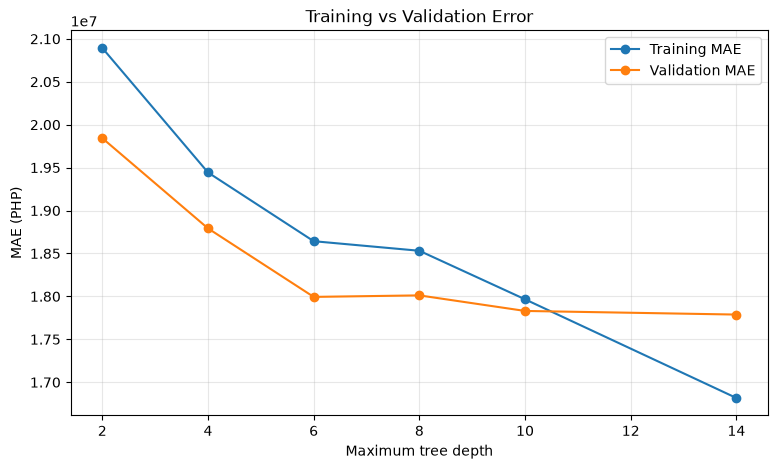

In [21]:
plt.figure(figsize=(9, 5))
plt.plot(
    reg_df['max_depth'],
    reg_df['MAE train'],
    marker='o',
    label='Training MAE'
)
plt.plot(
    reg_df['max_depth'],
    reg_df['MAE val'],
    marker='o',
    label='Validation MAE'
)
plt.xlabel('Maximum tree depth')
plt.ylabel('MAE (PHP)')
plt.title('Training vs Validation Error')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [22]:
best_idx = reg_df['MAE val'].idxmin()
best_params = reg_grid[best_idx]
best_tree = trees[best_idx]
print("Best parameters:")
print(best_params)
print("\nTraining MAE:",
      round(reg_df.loc[best_idx, 'MAE train'], 2))

print("Validation MAE:",
      round(reg_df.loc[best_idx, 'MAE val'], 2))
print("\nThe model was selected using the lowest validation MAE.")

Best parameters:
{'max_depth': 14, 'min_leaf': 3, 'min_split': 6}

Training MAE: 16816373.63
Validation MAE: 17788209.48

The model was selected using the lowest validation MAE.


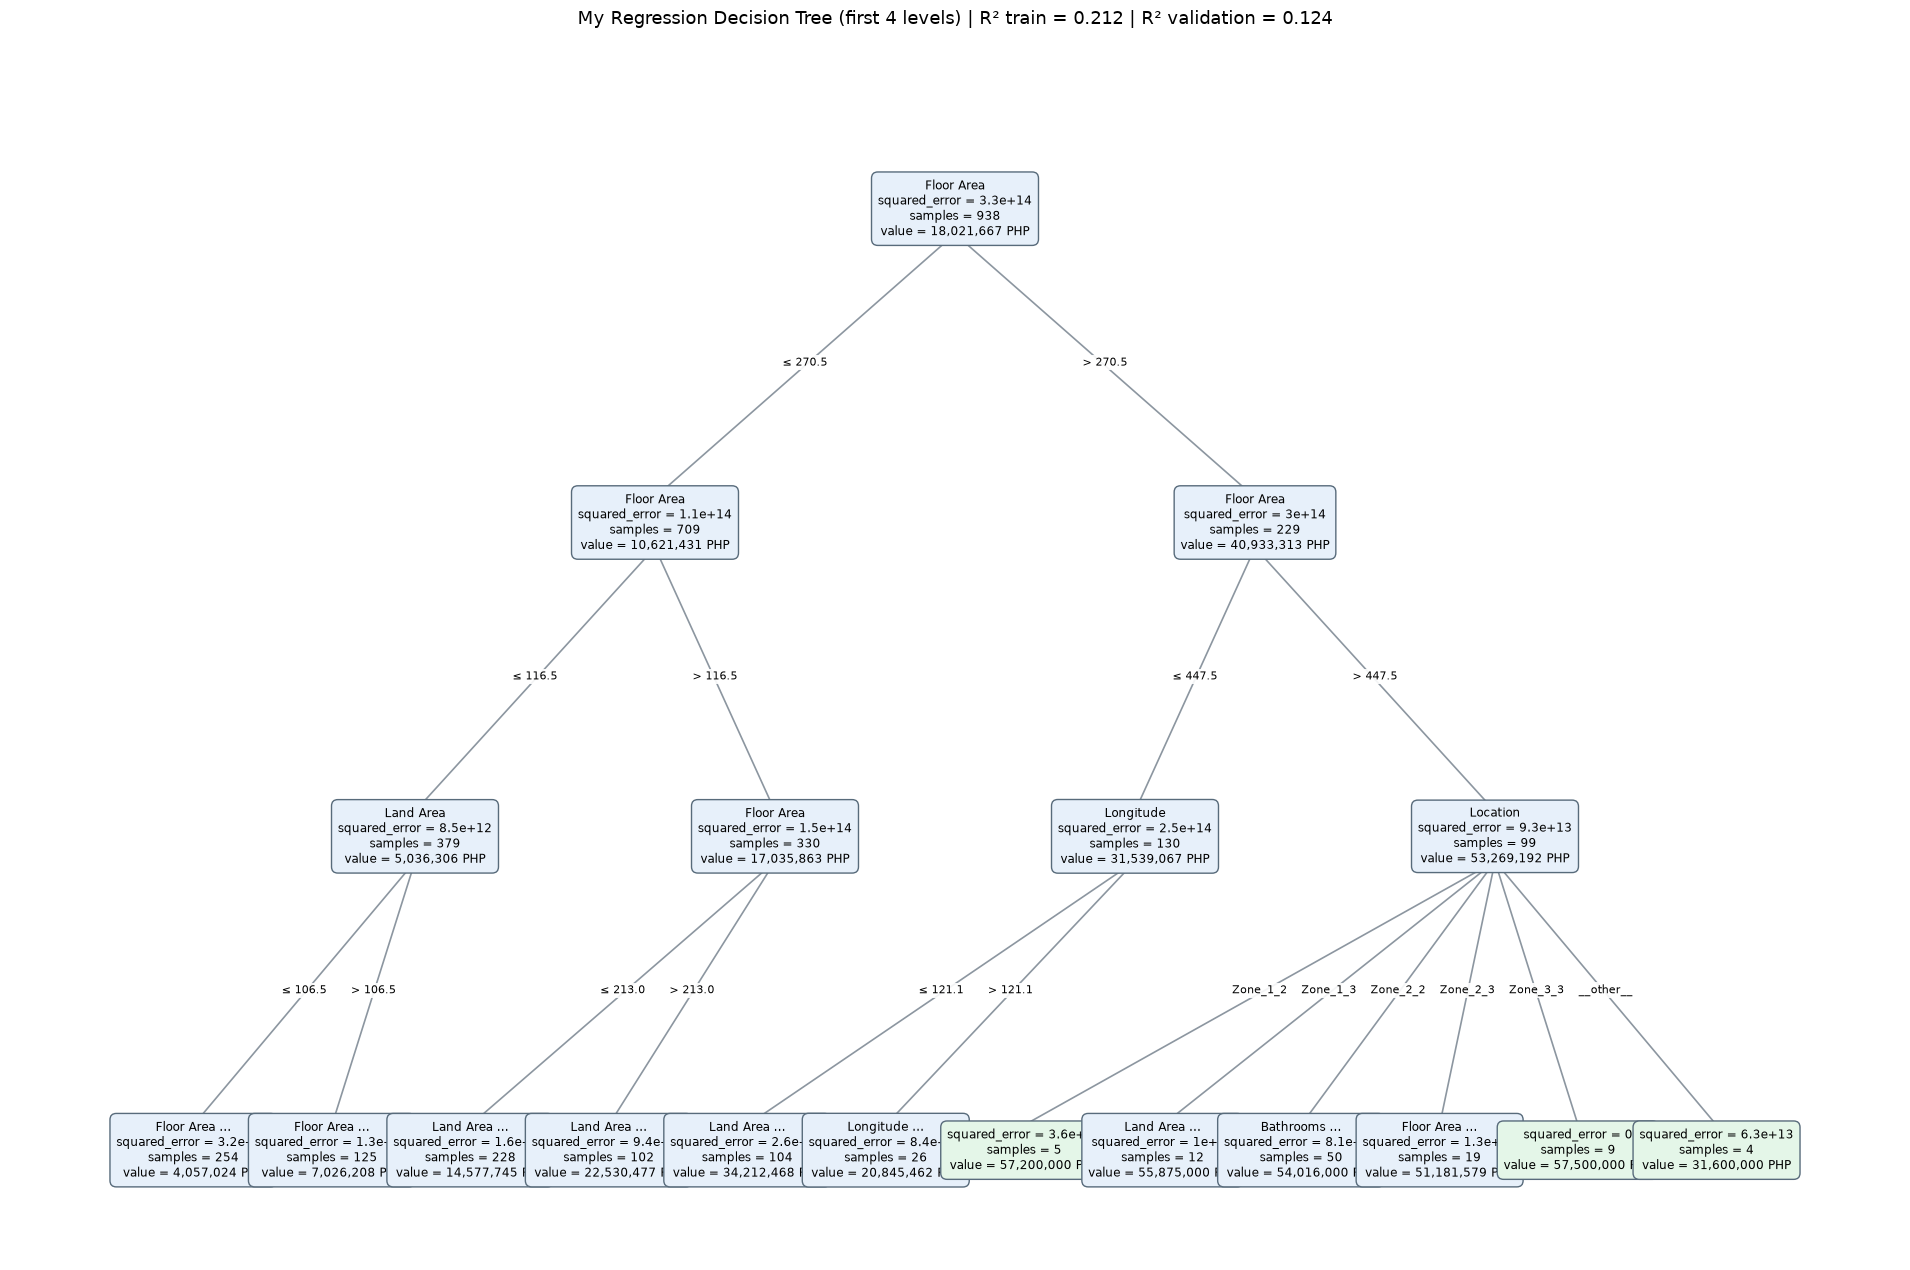

In [23]:
def plot_my_tree(tree, max_depth=3, title='My Decision Tree', r2_train=None, r2_val=None):
    from matplotlib.patches import FancyBboxPatch
    nodes, edges = [], []

    def visit(node, depth=0, parent=None, edge_label=''):
        idx = len(nodes)
        nodes.append((node, depth))
        if parent is not None:
            edges.append((parent, idx, edge_label))
        if depth >= max_depth - 1 or node.feat is None:
            return
        for key, child in node.kids.items():
            if node.thr is None:
                condition = str(key)
            else:
                condition = f'≤ {node.thr:.1f}' if key == 'le' else f'> {node.thr:.1f}'
            visit(child, depth + 1, idx, condition)

    visit(tree.root)
    levels = {}
    for i, (_, d) in enumerate(nodes):
        levels.setdefault(d, []).append(i)
    positions = {}
    for d, ids in levels.items():
        for j, i in enumerate(ids):
            positions[i] = ((j + 1) / (len(ids) + 1), -d)

    width = max(15, min(28, len(levels.get(max_depth-1, [])) * 1.6))
    fig, ax = plt.subplots(figsize=(width, 3.2 * max_depth))
    for parent, child, condition in edges:
        x1, y1 = positions[parent]
        x2, y2 = positions[child]
        ax.plot([x1, x2], [y1 - .08, y2 + .08], color='#8c96a0', lw=1.2, zorder=1)
        ax.text((x1+x2)/2, (y1+y2)/2, condition, fontsize=8, ha='center',
                bbox=dict(facecolor='white', edgecolor='none', alpha=.9, pad=1.5), zorder=3)
    for i, (node, d) in enumerate(nodes):
        x, y = positions[i]
        truncated = d == max_depth-1 and node.feat is not None
        if tree.task == 'reg':
            info = f'squared_error = {node.impurity:,.2g}\nsamples = {node.n}\nvalue = {node.value:,.0f} PHP'
        else:
            info = f'gini = {node.impurity:.3f}\nsamples = {node.n}\nclass = {int(node.value)}'
        if node.feat is None:
            label = info
        elif truncated:
            label = f'{node.feat} ...\n{info}'
        else:
            label = f'{node.feat}\n{info}'
        ax.text(x, y, label, ha='center', va='center', fontsize=8.3,
                bbox=dict(boxstyle='round,pad=.55', facecolor='#e7f0fa' if node.feat else '#e4f6e8',
                          edgecolor='#586b7b', linewidth=1), zorder=4)
    subtitle = ''
    if r2_train is not None and r2_val is not None:
        subtitle = f' | R² train = {r2_train:.3f} | R² validation = {r2_val:.3f}'
    ax.set_title(f'{title} (first {max_depth} levels){subtitle}', fontsize=13, pad=20)
    ax.set_xlim(-.025, 1.025)
    ax.set_ylim(-max_depth + .65, .5)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

plot_my_tree(best_tree, max_depth=4, title='My Regression Decision Tree',
             r2_train=reg_metrics(ytr_real, best_tree.predict(Xtr))['R2'],
             r2_val=reg_metrics(yva, best_tree.predict(Xva))['R2'])


The figure shows the first four levels of my regression decision tree.

Each node contains:
- **Feature**: the characteristic used to split the houses.
- **Squared error**: how much house prices vary inside the node.
- **Samples**: the number of houses in the node.
- **Value**: the average house price in PHP.

The tree first splits houses by Floor Area at 270.5. Houses with smaller floor areas go to the left, while larger houses go to the right. The next splits use Floor Area, Land Area, Longitude and Location.

The training R² is 0.212, while validation R² is 0.124. This means the model explains about 12.4% of price variation in the validation data and performs better on training data.

**2c. scikit-learn** (`DecisionTreeRegressor`, the library is allowed only for this comparison) with the same parameter sets. The test set is reserved for the last step, so train and validation sets are used here.

In [24]:
from sklearn.tree import DecisionTreeRegressor
A, B = sk_encode(Xtr, ytr, Xva)
sk_trees = []
sk_results = []

for params in reg_grid:
    model = DecisionTreeRegressor(
        max_depth=params['max_depth'],
        min_samples_leaf=params['min_leaf'],
        min_samples_split=params['min_split'],
        random_state=SEED
    )
    # train the model on the training data 
    model.fit(A, ytr)
    # make predictions on the training and validation data
    train_pred = model.predict(A)
    val_pred = model.predict(B)
    train_metrics = reg_metrics(ytr_real, train_pred)
    val_metrics = reg_metrics(yva, val_pred)
    sk_results.append(row(params, train_metrics, val_metrics))
    sk_trees.append(model)

sk_reg_df = pd.DataFrame(sk_results)

display(sk_reg_df.round(3))

,max_depth,min_leaf,min_split,MSE train,MAE train,MAPE % train,R2 train,MSE val,MAE val,MAPE % val,R2 val
0,2,20,40,4.601785e+15,2.063738e+07,73.953,0.163,8.179011e+15,1.947159e+07,70.186,0.102
1,4,20,40,4.488352e+15,1.928634e+07,53.543,0.184,8.053937e+15,1.857555e+07,54.175,0.116
2,6,10,20,4.412668e+15,1.816139e+07,43.471,0.198,8.042935e+15,1.826140e+07,52.750,0.117
3,8,10,20,4.409359e+15,1.799469e+07,39.647,0.198,8.043139e+15,1.834618e+07,51.173,0.117
4,10,5,10,4.355155e+15,1.721091e+07,31.585,0.208,7.981468e+15,1.804990e+07,49.362,0.124
5,14,3,6,4.316625e+15,1.637889e+07,23.426,0.215,7.976724e+15,1.793517e+07,53.004,0.124


In [25]:
comparison = pd.DataFrame({
    'max_depth': reg_df['max_depth'],
    'min_leaf': reg_df['min_leaf'],
    'min_split': reg_df['min_split'],
    'MyTree MAE': reg_df['MAE val'],
    'Sklearn MAE': sk_reg_df['MAE val'],
    'MyTree MSE': reg_df['MSE val'],
    'Sklearn MSE': sk_reg_df['MSE val']
})

display(comparison.round(2))

print("Best MyTree validation MAE:",
      round(reg_df['MAE val'].min(), 2))

print("Best sklearn validation MAE:",
      round(sk_reg_df['MAE val'].min(), 2))

,max_depth,min_leaf,min_split,MyTree MAE,Sklearn MAE,MyTree MSE,Sklearn MSE
0,2,20,40,19843030.42,19471594.35,8.176201e+15,8.179011e+15
1,4,20,40,18792138.38,18575549.62,8.079786e+15,8.053937e+15
2,6,10,20,17994054.93,18261398.81,8.047334e+15,8.042935e+15
3,8,10,20,18011733.68,18346181.22,8.046853e+15,8.043139e+15
4,10,5,10,17830462.62,18049902.30,7.995175e+15,7.981468e+15
5,14,3,6,17788209.48,17935174.10,7.977770e+15,7.976724e+15


Best MyTree validation MAE: 17788209.48
Best sklearn validation MAE: 17935174.1


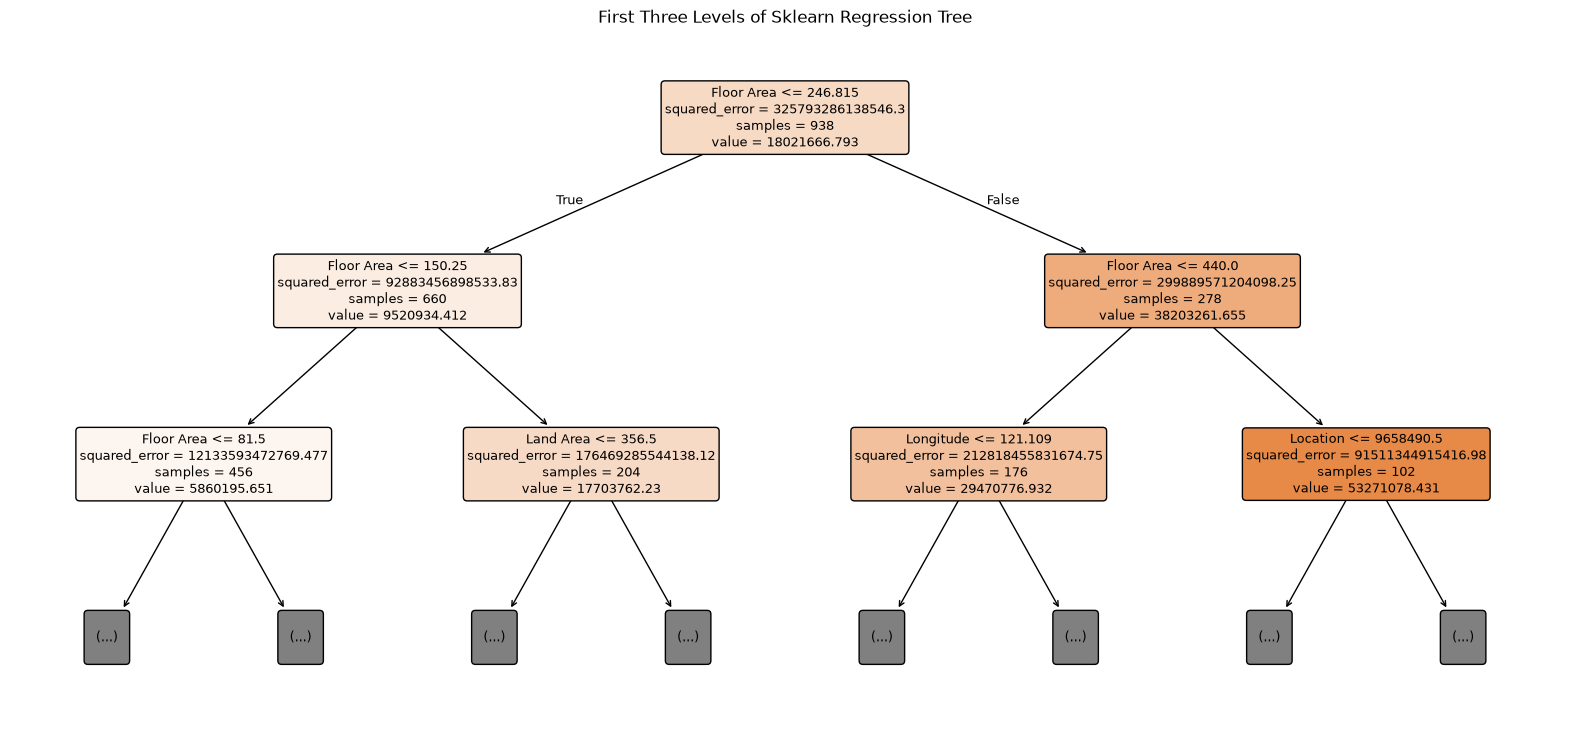

In [26]:
from sklearn.tree import plot_tree

best_sk_idx = sk_reg_df['MAE val'].idxmin()
best_sk_tree = sk_trees[best_sk_idx]

plt.figure(figsize=(20, 9))

plot_tree(
    best_sk_tree,
    feature_names=A.columns,
    max_depth=2,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('First Three Levels of Sklearn Regression Tree')
plt.show()

## 3. Classification Decision Tree

In this part, I used a decision tree to predict house price categories instead of exact prices.

First, I divided the prices into five classes using the 20th, 40th, 60th and 80th percentiles of the training data. I used the same boundaries for the validation data.

I implemented the classification tree myself using the `MyTree` class from the previous section, but changed the task to `cls`. For classification, the tree uses Gini impurity to find the best splits and predicts the most common class in each leaf. 
I tested six combinations of tree parameters and selected the best model based on validation accuracy. I also calculated precision, sensitivity (recall) and specificity, and used confusion matrices to see which price categories the model predicted correctly and where it made mistakes.

In [27]:
# Calculate class boundaries using original training prices
edges = np.quantile(ytr_real, [0.2, 0.4, 0.6, 0.8])
def to_cls(prices):
    return np.searchsorted(edges, prices, side='right')

# Convert prices into classes(classification predicts categories instead of exact prices. I divided house prices into five groups using training percentiles.)
ctr = to_cls(ytr_real)
cva = to_cls(yva)

print("Class boundaries:", edges)
print("Training class counts:", np.bincount(ctr, minlength=5))
print("Validation class counts:", np.bincount(cva, minlength=5))

Class boundaries: [ 4263000.          7500000.         14000000.         30666600.00000003]
Training class counts: [187 186 187 190 188]
Validation class counts: [38 49 40 39 35]


In [28]:
# confusion matrix for classification tasks, which shows the number of correct and incorrect predictions for each class
def confusion(y_true, y_pred, k=5):
    cm = np.zeros((k, k), dtype=int)

    for actual, predicted in zip(y_true, y_pred):
        cm[actual, predicted] += 1

    return cm


# accuracy shows the proportion of correct predictions, 
# precision measures the accuracy of positive predictions, 
# sensitivity measures the ability to identify positive instances,
# specificity measures the ability to identify negative instances
def cls_metrics(y_true, y_pred, k=5):
    cm = confusion(y_true, y_pred, k)
    accuracy = np.trace(cm) / cm.sum()
    precisions = []
    sensitivities = []
    specificities = []
    for i in range(k):
        TP = cm[i, i]
        FP = cm[:, i].sum() - TP
        FN = cm[i, :].sum() - TP
        TN = cm.sum() - TP - FP - FN

        precision = TP / (TP + FP) if TP + FP > 0 else 0
        sensitivity = TP / (TP + FN) if TP + FN > 0 else 0
        specificity = TN / (TN + FP) if TN + FP > 0 else 0

        precisions.append(precision)
        sensitivities.append(sensitivity)
        specificities.append(specificity)

    return {
        'accuracy': accuracy,
        'precision': np.mean(precisions),
        'sensitivity': np.mean(sensitivities),
        'specificity': np.mean(specificities)
    }

In [29]:
ctrees = []
results = []

for params in reg_grid:

    tree = MyTree(
        task='cls',
        max_depth=params['max_depth'],
        min_leaf=params['min_leaf'],
        min_split=params['min_split'],
        n_thr=5,
        seed=SEED
    )

    tree.fit(Xtr, ctr)

    train_pred = tree.predict(Xtr)
    val_pred = tree.predict(Xva)

    train_metrics = cls_metrics(ctr, train_pred)
    val_metrics = cls_metrics(cva, val_pred)

    results.append(row(params, train_metrics, val_metrics))
    ctrees.append(tree)

cls_df = pd.DataFrame(results)

display(cls_df.round(3))

,max_depth,min_leaf,min_split,accuracy train,precision train,sensitivity train,specificity train,accuracy val,precision val,sensitivity val,specificity val
0,2,20,40,0.564,0.476,0.563,0.891,0.547,0.465,0.578,0.888
1,4,20,40,0.636,0.662,0.636,0.909,0.617,0.637,0.623,0.904
2,6,10,20,0.699,0.710,0.699,0.925,0.612,0.625,0.622,0.902
3,8,10,20,0.713,0.719,0.713,0.928,0.632,0.642,0.643,0.907
4,10,5,10,0.772,0.773,0.772,0.943,0.672,0.683,0.684,0.917
5,14,3,6,0.839,0.840,0.839,0.960,0.637,0.643,0.646,0.909


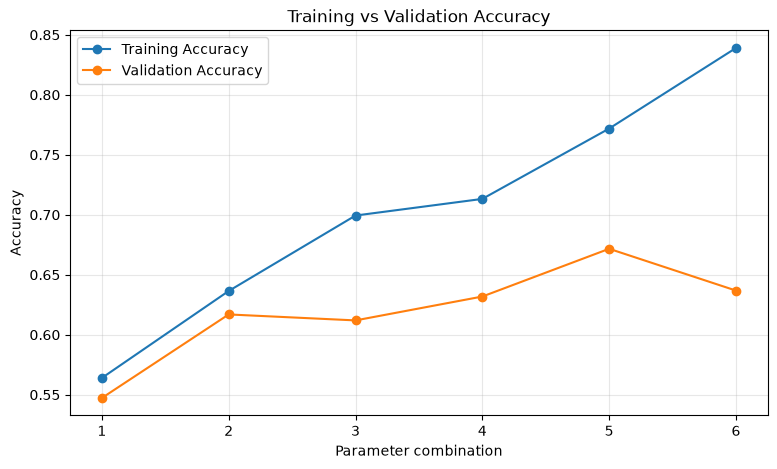

In [30]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cls_df) + 1),
    cls_df['accuracy train'],
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    range(1, len(cls_df) + 1),
    cls_df['accuracy val'],
    marker='o',
    label='Validation Accuracy'
)

plt.xticks(range(1, len(cls_df) + 1))
plt.xlabel('Parameter combination')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [31]:
best_cls_idx = cls_df['accuracy val'].idxmax()

best_cls_params = reg_grid[best_cls_idx]
best_cls_tree = ctrees[best_cls_idx]

print("Best parameters:", best_cls_params)

print(
    "Training accuracy:",
    round(cls_df.loc[best_cls_idx, 'accuracy train'], 3)
)

print(
    "Validation accuracy:",
    round(cls_df.loc[best_cls_idx, 'accuracy val'], 3)
)

print("The model was selected using the highest validation accuracy.")

Best parameters: {'max_depth': 10, 'min_leaf': 5, 'min_split': 10}
Training accuracy: 0.772
Validation accuracy: 0.672
The model was selected using the highest validation accuracy.


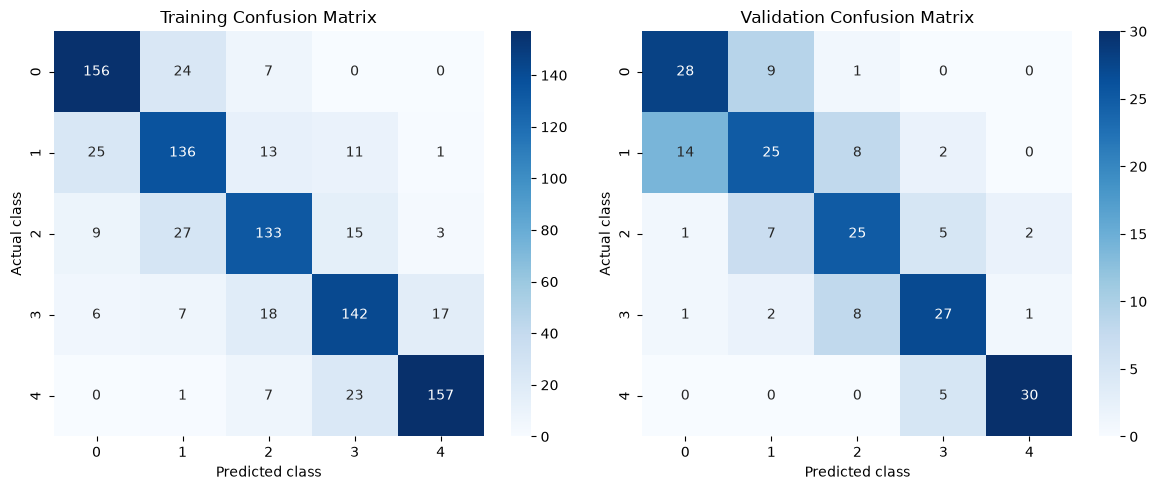

In [32]:
train_pred = best_cls_tree.predict(Xtr)
val_pred = best_cls_tree.predict(Xva)

train_cm = confusion(ctr, train_pred)
val_cm = confusion(cva, val_pred)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    train_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0]
)

axes[0].set_title('Training Confusion Matrix')
axes[0].set_xlabel('Predicted class')
axes[0].set_ylabel('Actual class')

sns.heatmap(
    val_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[1]
)

axes[1].set_title('Validation Confusion Matrix')
axes[1].set_xlabel('Predicted class')
axes[1].set_ylabel('Actual class')

plt.tight_layout()
plt.show()

The training confusion matrix has larger values because it contains more houses than the validation dataset. Most correct predictions are on the main diagonal.

The model achieved 77.2% accuracy on training data and 67.2% on validation data. In validation, class 4 had the highest percentage of correct predictions (85.7%), while class 1 had the lowest (51.0%).

Most mistakes were between neighboring price categories. This may happen because houses in these categories have similar features. The lower validation accuracy also suggests some overfitting.

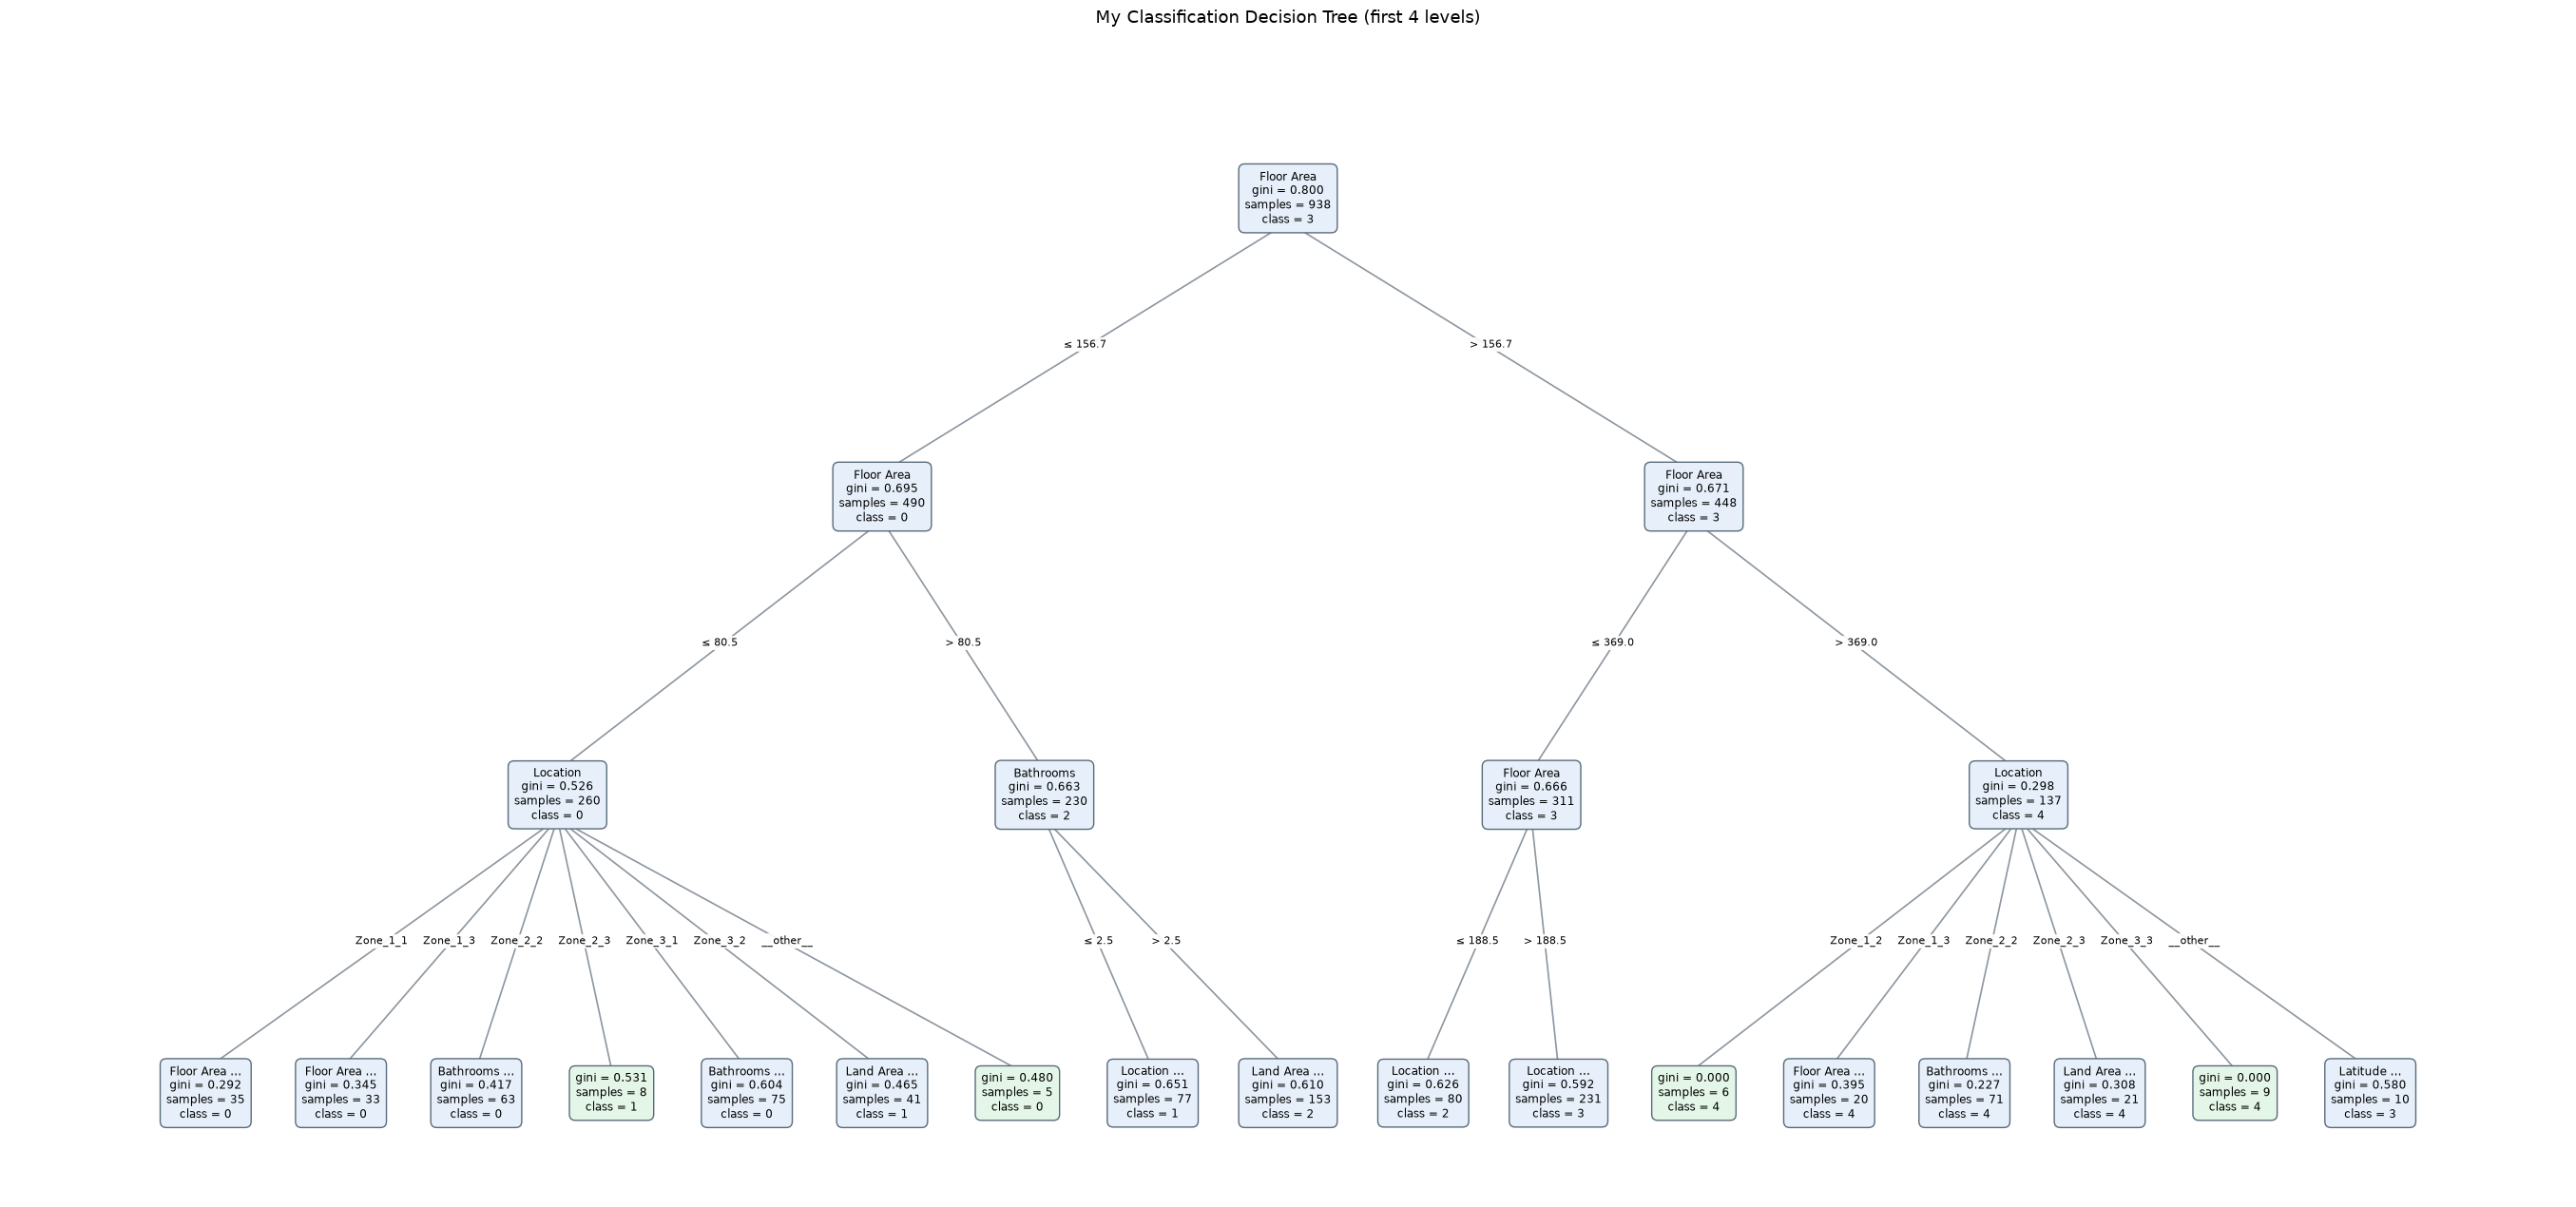

In [33]:
plot_my_tree(best_cls_tree, max_depth=4, title='My Classification Decision Tree')

**3d. scikit-learn** (`DecisionTreeClassifier`) with the same parameter sets (train and validation sets; the test set is kept for the end).

In [34]:
from sklearn.tree import DecisionTreeClassifier

sk_cls_trees = []
sk_results = []

for params in reg_grid:

    model = DecisionTreeClassifier(
        max_depth=params['max_depth'],
        min_samples_leaf=params['min_leaf'],
        min_samples_split=params['min_split'],
        random_state=SEED
    )

    model.fit(A, ctr)

    train_pred = model.predict(A)
    val_pred = model.predict(B)

    train_metrics = cls_metrics(ctr, train_pred)
    val_metrics = cls_metrics(cva, val_pred)

    sk_results.append(row(params, train_metrics, val_metrics))
    sk_cls_trees.append(model)

sk_cls_df = pd.DataFrame(sk_results)

display(sk_cls_df.round(3))

,max_depth,min_leaf,min_split,accuracy train,precision train,sensitivity train,specificity train,accuracy val,precision val,sensitivity val,specificity val
0,2,20,40,0.579,0.512,0.578,0.895,0.547,0.504,0.576,0.887
1,4,20,40,0.682,0.698,0.682,0.921,0.672,0.688,0.683,0.917
2,6,10,20,0.746,0.750,0.746,0.937,0.677,0.691,0.683,0.918
3,8,10,20,0.769,0.769,0.769,0.942,0.672,0.678,0.680,0.917
4,10,5,10,0.808,0.808,0.808,0.952,0.677,0.686,0.687,0.919
5,14,3,6,0.861,0.862,0.861,0.965,0.672,0.675,0.678,0.917


In [35]:
comparison_cls = pd.DataFrame({
    'max_depth': cls_df['max_depth'],
    'min_leaf': cls_df['min_leaf'],
    'min_split': cls_df['min_split'],
    'MyTree accuracy': cls_df['accuracy val'],
    'Sklearn accuracy': sk_cls_df['accuracy val'],
    'MyTree precision': cls_df['precision val'],
    'Sklearn precision': sk_cls_df['precision val'],
    'MyTree sensitivity': cls_df['sensitivity val'],
    'Sklearn sensitivity': sk_cls_df['sensitivity val'],
    'MyTree specificity': cls_df['specificity val'],
    'Sklearn specificity': sk_cls_df['specificity val']
})

display(comparison_cls.round(3))

print("Best MyTree validation accuracy:",
      round(cls_df['accuracy val'].max(), 3))

print("Best sklearn validation accuracy:",
      round(sk_cls_df['accuracy val'].max(), 3))

,max_depth,min_leaf,min_split,MyTree accuracy,Sklearn accuracy,MyTree precision,Sklearn precision,MyTree sensitivity,Sklearn sensitivity,MyTree specificity,Sklearn specificity
0,2,20,40,0.547,0.547,0.465,0.504,0.578,0.576,0.888,0.887
1,4,20,40,0.617,0.672,0.637,0.688,0.623,0.683,0.904,0.917
2,6,10,20,0.612,0.677,0.625,0.691,0.622,0.683,0.902,0.918
3,8,10,20,0.632,0.672,0.642,0.678,0.643,0.680,0.907,0.917
4,10,5,10,0.672,0.677,0.683,0.686,0.684,0.687,0.917,0.919
5,14,3,6,0.637,0.672,0.643,0.675,0.646,0.678,0.909,0.917


Best MyTree validation accuracy: 0.672
Best sklearn validation accuracy: 0.677


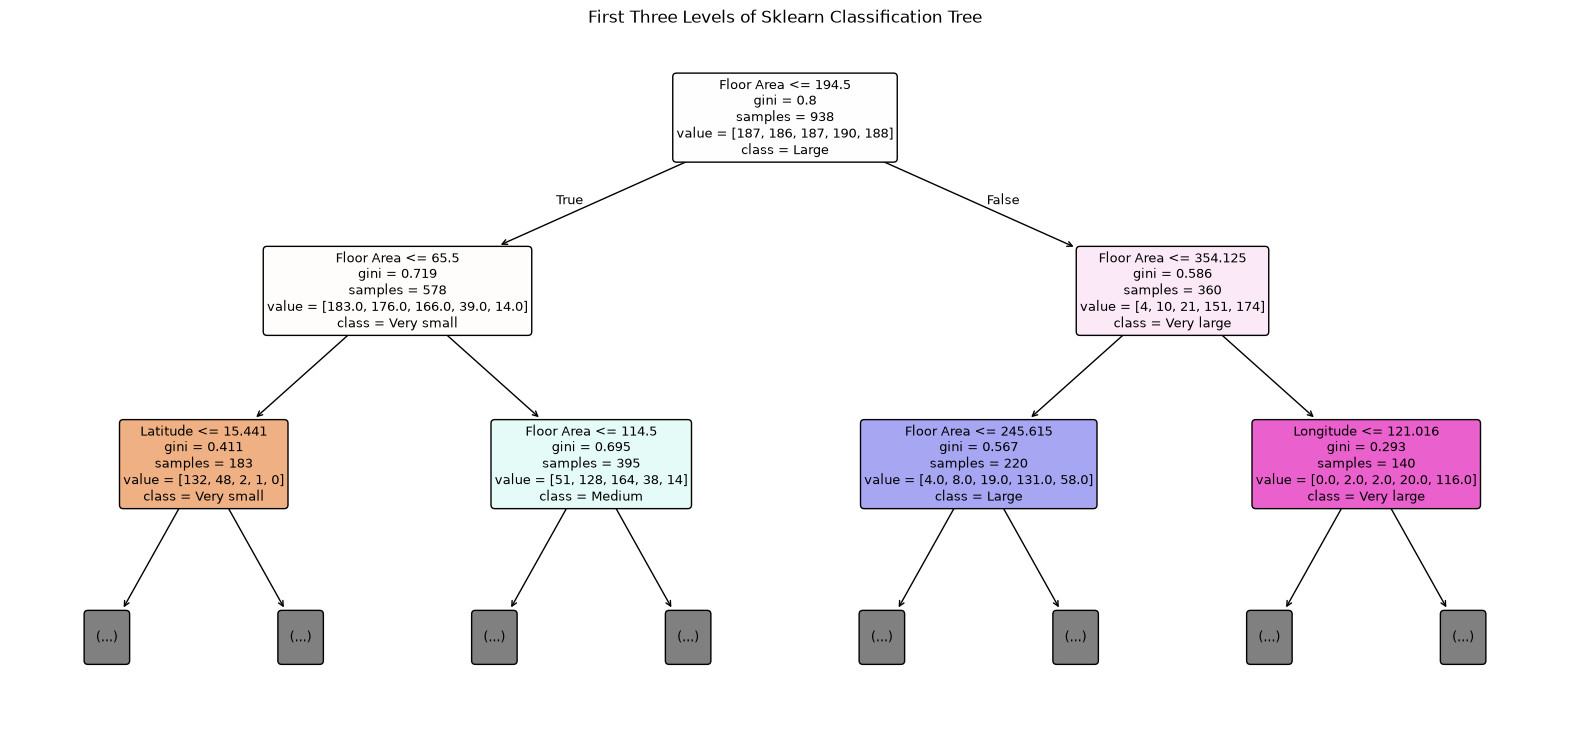

In [36]:
from sklearn.tree import plot_tree

best_sk_cls_idx = sk_cls_df['accuracy val'].idxmax()
best_sk_cls_tree = sk_cls_trees[best_sk_cls_idx]

plt.figure(figsize=(20, 9))

plot_tree(
    best_sk_cls_tree,
    feature_names=A.columns,
    class_names=[
        'Very small',
        'Small',
        'Medium',
        'Large',
        'Very large'
    ],
    max_depth=2,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('First Three Levels of Sklearn Classification Tree')
plt.show()

## 4. Regression Random Forest

A Random Forest regressor is implemented from scratch using MyTree.

First, I implemented my own Random Forest using the MyTree class. Each tree is trained on a different bootstrap sample and considers random features at each split. The final prediction is the average of all trees. Then I prepared five cross-validation folds to evaluate the model more reliably. I also performed preprocessing separately for each fold to avoid data leakage.

The same parameter combinations are tested with scikit-learn. Finally, the selected model is evaluated on the untouched test set.

In [37]:
class MyForest:
    def __init__(self, n_trees=10, max_features=3, seed=0, **tree_kw):
        self.n_trees = n_trees
        self.max_features = max_features
        self.seed = seed
        self.tree_kw = tree_kw

    def fit(self, X, y):
        rng = np.random.default_rng(self.seed)
        y = np.asarray(y)

        self.trees = []

        for i in range(self.n_trees):
            # Bootstrap: random sampling with replacement
            indices = rng.integers(0, len(X), size=len(X))

            X_sample = X.iloc[indices].reset_index(drop=True)
            y_sample = y[indices]

            tree = MyTree(
                task='reg',
                max_features=self.max_features,
                seed=self.seed + i,
                **self.tree_kw
            )

            tree.fit(X_sample, y_sample)
            self.trees.append(tree)

        return self

    def predict(self, X):
        predictions = []

        for tree in self.trees:
            predictions.append(tree.predict(X))

        return np.mean(predictions, axis=0)

In [38]:
K = 5

rng = np.random.default_rng(SEED)
indices = rng.permutation(len(dev_data))
parts = np.array_split(indices, K)

folds = []
sk_folds = []

for i in range(K):
    train_idx = np.concatenate([
        parts[j] for j in range(K) if j != i
    ])
    val_idx = parts[i]

    fold_train = dev_data.iloc[train_idx]
    fold_val = dev_data.iloc[val_idx]

    # Preprocessing fitted only on this fold's training data
    Xa, ya, Xb, yb, _ = prepare(fold_train, fold_val)

    folds.append((Xa, ya, Xb, yb))

    # Encoding only for sklearn
    A_fold, B_fold = sk_encode(Xa, ya, Xb)
    sk_folds.append((A_fold, B_fold, ya, yb))

print("Number of folds:", len(folds))

for i, (Xa, ya, Xb, yb) in enumerate(folds):
    print(
        f"Fold {i + 1}: "
        f"train = {len(Xa)}, validation = {len(Xb)}"
    )

Number of folds: 5
Fold 1: train = 911, validation = 228
Fold 2: train = 911, validation = 228
Fold 3: train = 911, validation = 228
Fold 4: train = 911, validation = 228
Fold 5: train = 912, validation = 227


C:\Users\Поліна\AppData\Local\Temp\ipykernel_18812\3150696230.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_df = df.select_dtypes(include=["object"])
C:\Users\Поліна\AppData\Local\Temp\ipykernel_18812\3150696230.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide

Number of combinations: 27


,trees,depth,min_leaf,MAE mean,MAE std
15,10,8,5,18695826.95,2652980.89
24,15,8,5,18707667.26,2621510.81
6,5,8,5,18867043.98,2688254.14
21,15,6,5,18882922.79,2660296.42
16,10,8,10,18930113.84,2651162.83
25,15,8,10,18933216.89,2654371.95
12,10,6,5,18938688.72,2682629.74
22,15,6,10,19046480.25,2644461.49
13,10,6,10,19047033.15,2611384.43
3,5,6,5,19093546.31,2790855.41


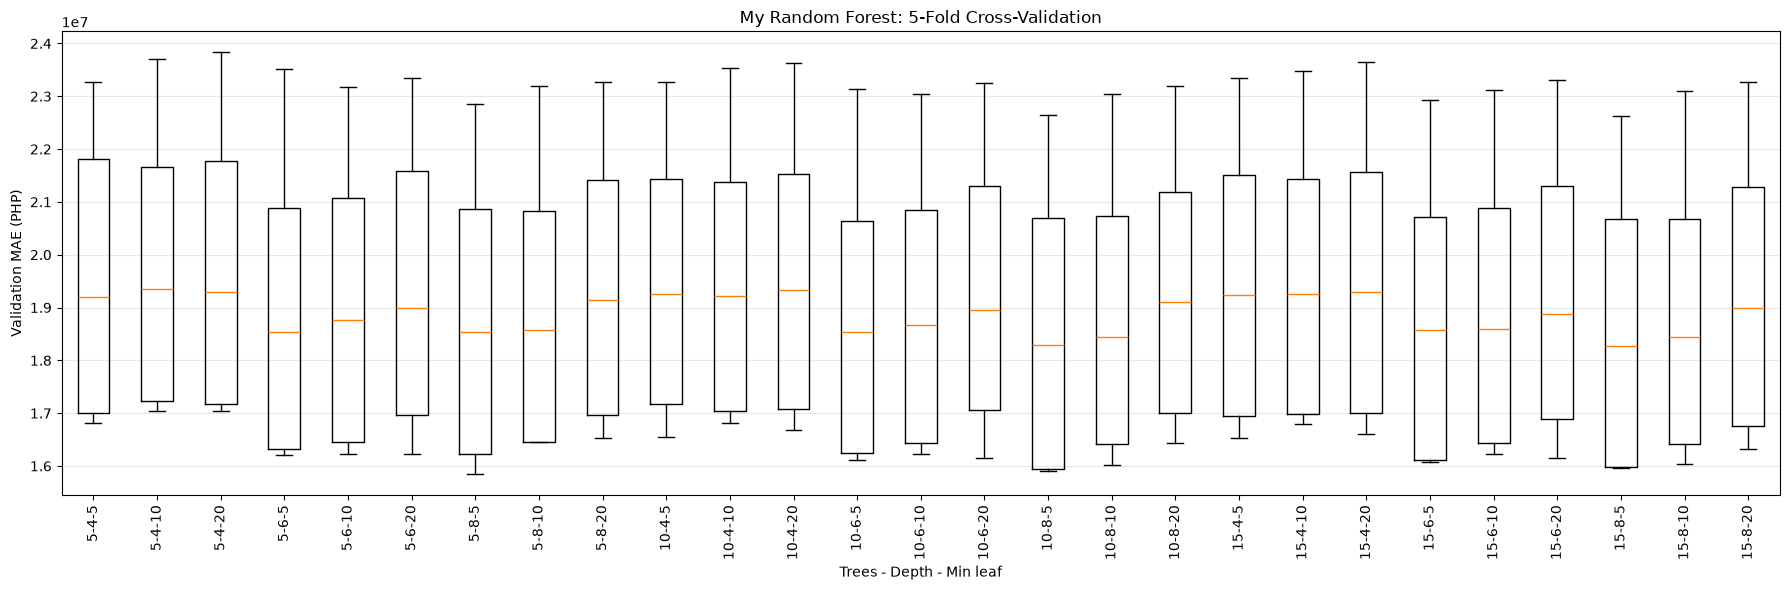

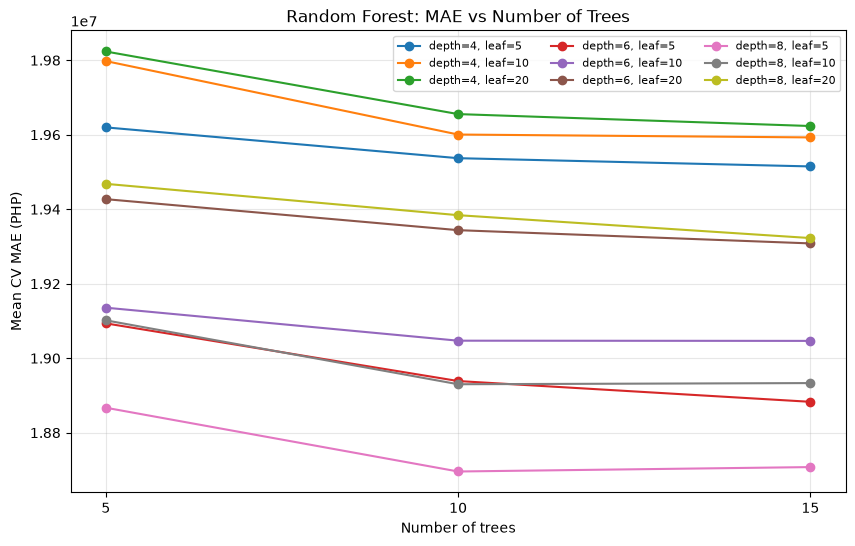

Best parameters:
Number of trees: 10
Maximum depth: 8
Minimum leaf size: 5
Mean CV MAE: 18695826.95

Average MAE by number of trees:


trees
5     19370446.69
10    19236935.89
15    19214682.43
Name: MAE mean, dtype: float64


MAE change from 5 to 15 trees: -0.80%
On average, 15 trees performed better than 5 trees.


In [39]:
combos = [
    (n_trees, depth, leaf)
    for n_trees in [5, 10, 15]
    for depth in [4, 6, 8]
    for leaf in [5, 10, 20]
]

print("Number of combinations:", len(combos))

cv = {}
results = []

for n_trees, depth, leaf in combos:
    fold_errors = []

    for Xa, ya, Xb, yb in folds:

        model = MyForest(
            n_trees=n_trees,
            max_features=3,
            max_depth=depth,
            min_leaf=leaf,
            min_split=2 * leaf,
            seed=SEED
        )

        model.fit(Xa, ya)
        predictions = model.predict(Xb)

        mae = np.mean(np.abs(yb - predictions))
        fold_errors.append(mae)

    params = (n_trees, depth, leaf)
    cv[params] = fold_errors

    results.append({
        'trees': n_trees,
        'depth': depth,
        'min_leaf': leaf,
        'MAE mean': np.mean(fold_errors),
        'MAE std': np.std(fold_errors)
    })

cv_df = pd.DataFrame(results)

display(cv_df.sort_values('MAE mean').round(2))

labels = [
    f'{t}-{d}-{l}'
    for t, d, l in combos
]

plt.figure(figsize=(18, 6))

plt.boxplot(
    [cv[c] for c in combos],
    tick_labels=labels
)

plt.xticks(rotation=90)
plt.xlabel('Trees - Depth - Min leaf')
plt.ylabel('Validation MAE (PHP)')
plt.title('My Random Forest: 5-Fold Cross-Validation')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()
plt.figure(figsize=(10, 6))

for (depth, leaf), group in cv_df.groupby(['depth', 'min_leaf']):
    group = group.sort_values('trees')

    plt.plot(
        group['trees'],
        group['MAE mean'],
        marker='o',
        label=f'depth={depth}, leaf={leaf}'
    )

plt.xticks([5, 10, 15])
plt.xlabel('Number of trees')
plt.ylabel('Mean CV MAE (PHP)')
plt.title('Random Forest: MAE vs Number of Trees')
plt.legend(fontsize=8, ncol=3)
plt.grid(alpha=0.3)
plt.show()

# Find the best parameters based on the lowest mean MAE across folds
best = min(cv, key=lambda params: np.mean(cv[params]))
print("Best parameters:")
print("Number of trees:", best[0])
print("Maximum depth:", best[1])
print("Minimum leaf size:", best[2])

print(
    "Mean CV MAE:",
    round(np.mean(cv[best]), 2)
)

print("\nAverage MAE by number of trees:")

by_trees = cv_df.groupby('trees')['MAE mean'].mean()
display(by_trees.round(2))

change = (by_trees.loc[15] / by_trees.loc[5] - 1) * 100

print(f"\nMAE change from 5 to 15 trees: {change:.2f}%")

if change < 0:
    print("On average, 15 trees performed better than 5 trees.")
elif change > 0:
    print("On average, 15 trees performed worse than 5 trees.")
else:
    print("The average MAE did not change.")

,trees,depth,min_leaf,MAE mean,MAE std
24,15,8,5,18685400.10,2692476.69
15,10,8,5,18768611.53,2697374.22
21,15,6,5,18820878.05,2583934.44
12,10,6,5,18837411.90,2514721.02
6,5,8,5,18889511.55,2726732.43
3,5,6,5,18935310.09,2515501.42
25,15,8,10,18975098.75,2615431.62
22,15,6,10,19049285.59,2670151.96
16,10,8,10,19061033.98,2602422.19
13,10,6,10,19062887.16,2631167.69


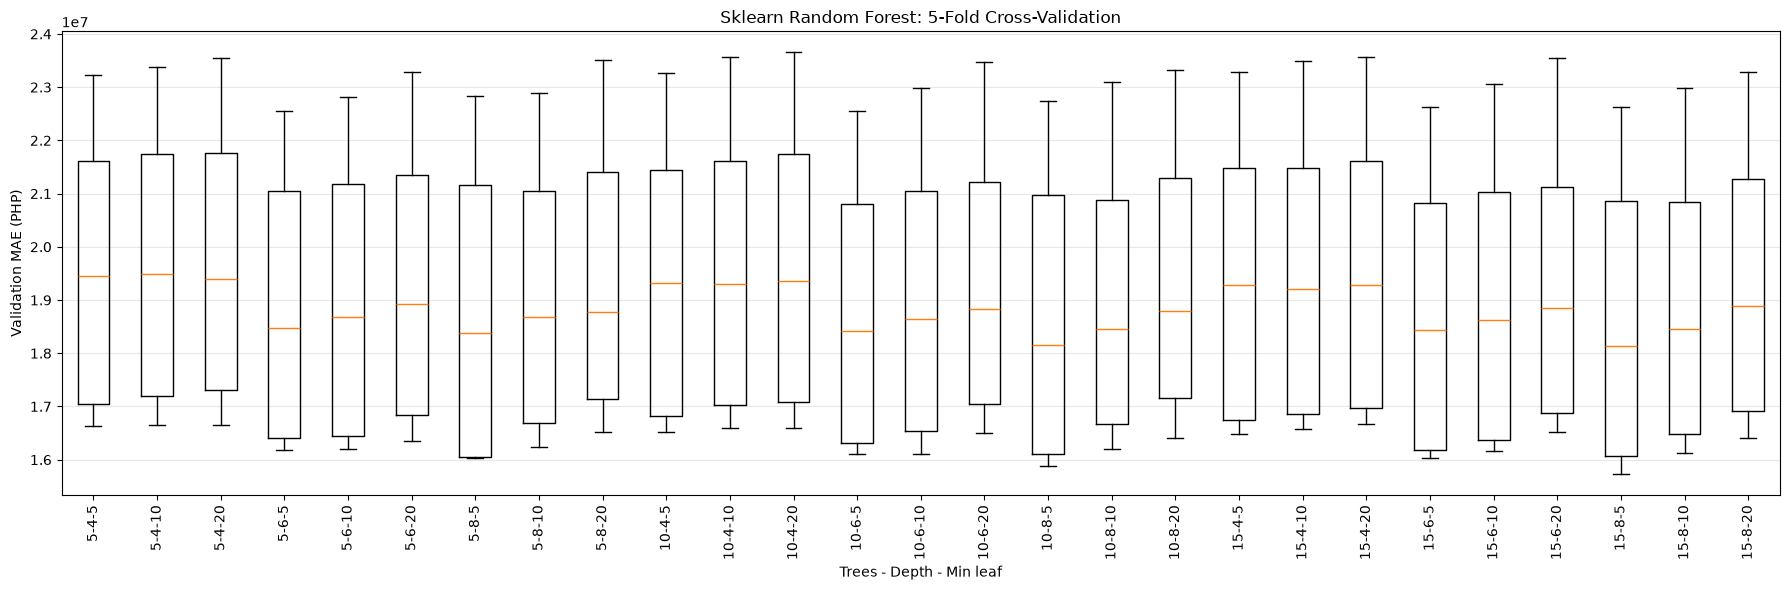

,trees,depth,min_leaf,MyForest MAE,Sklearn MAE
0,5,4,5,19619697.35,19596802.84
1,5,4,10,19797746.70,19694859.32
2,5,4,20,19823475.33,19731018.10
3,5,6,5,19093546.31,18935310.09
4,5,6,10,19135643.98,19067802.41
5,5,6,20,19427017.80,19353382.90
6,5,8,5,18867043.98,18889511.55
7,5,8,10,19101702.32,19110067.81
8,5,8,20,19468146.44,19472113.96
9,10,4,5,19537028.01,19475071.40


Best MyForest parameters: (10, 8, 5)
Best sklearn parameters: (15, 8, 5)
Best MyForest CV MAE: 18695826.95
Best sklearn CV MAE: 18685400.1


In [40]:
from sklearn.ensemble import RandomForestRegressor

cv_sk = {}
sk_results = []

for n_trees, depth, leaf in combos:
    fold_errors = []

    for A_fold, B_fold, ya, yb in sk_folds:

        model = RandomForestRegressor(
            n_estimators=n_trees,
            max_features=3,
            max_depth=depth,
            min_samples_leaf=leaf,
            min_samples_split=2 * leaf,
            random_state=SEED,
            n_jobs=-1
        )

        model.fit(A_fold, ya)
        predictions = model.predict(B_fold)

        mae = np.mean(np.abs(yb - predictions))
        fold_errors.append(mae)

    params = (n_trees, depth, leaf)
    cv_sk[params] = fold_errors

    sk_results.append({
        'trees': n_trees,
        'depth': depth,
        'min_leaf': leaf,
        'MAE mean': np.mean(fold_errors),
        'MAE std': np.std(fold_errors)
    })

sk_cv_df = pd.DataFrame(sk_results)

display(sk_cv_df.sort_values('MAE mean').round(2))

plt.figure(figsize=(18, 6))

plt.boxplot(
    [cv_sk[c] for c in combos],
    tick_labels=labels
)

plt.xticks(rotation=90)
plt.xlabel('Trees - Depth - Min leaf')
plt.ylabel('Validation MAE (PHP)')
plt.title('Sklearn Random Forest: 5-Fold Cross-Validation')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

comparison_rf = pd.DataFrame({
    'trees': [c[0] for c in combos],
    'depth': [c[1] for c in combos],
    'min_leaf': [c[2] for c in combos],
    'MyForest MAE': [np.mean(cv[c]) for c in combos],
    'Sklearn MAE': [np.mean(cv_sk[c]) for c in combos]
})

display(comparison_rf.round(2))

best_sk = min(
    cv_sk,
    key=lambda params: np.mean(cv_sk[params])
)

print("Best MyForest parameters:", best)
print("Best sklearn parameters:", best_sk)

print(
    "Best MyForest CV MAE:",
    round(np.mean(cv[best]), 2)
)

print(
    "Best sklearn CV MAE:",
    round(np.mean(cv_sk[best_sk]), 2)
)

### 4d. Model for unseen data
The final model uses the selected number of trees and tree parameters, is trained on train+validation (`dev_data`) with the preprocessing fitted on `dev_data`. The test set is used here for the first time. The model is saved as plain dictionaries, so `predict.py` works without training and without this notebook.

In [41]:
Xd, yd, Xt, yt, prep_final = prepare(
    dev_data,
    test_data
)

forest = MyForest(
    n_trees=best[0],
    max_features=3,
    max_depth=best[1],
    min_leaf=best[2],
    min_split=2 * best[2],
    seed=SEED
)

forest.fit(Xd, yd)

pred = forest.predict(Xt)

print("Final model trained.")
print("Number of trees:", len(forest.trees))

C:\Users\Поліна\AppData\Local\Temp\ipykernel_18812\3150696230.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_df = df.select_dtypes(include=["object"])


Final model trained.
Number of trees: 10


In [42]:
A_final, B_final = sk_encode(Xd, yd, Xt)

sk_rf = RandomForestRegressor(
    n_estimators=best[0],
    max_features=3,
    max_depth=best[1],
    min_samples_leaf=best[2],
    min_samples_split=2 * best[2],
    random_state=SEED,
    n_jobs=-1
)

sk_rf.fit(A_final, yd)
sk_pred = sk_rf.predict(B_final)

test_results = pd.DataFrame({
    'MyForest': reg_metrics(yt, pred),
    'Sklearn': reg_metrics(yt, sk_pred)
}).T

display(test_results.round(3))

,MSE,MAE,MAPE %,R2
MyForest,3.547637e+16,3.025499e+07,41.138,0.044
Sklearn,3.545700e+16,3.011437e+07,40.961,0.045


### Visualizing trees inside the Random Forest

A Random Forest contains many individual decision trees. The following plots show the first three levels of two trees from my forest and two trees from scikit-learn. Different bootstrap samples and random feature selection lead to different split structures. The R² values in my tree titles are calculated from predictions, while squared error inside a node describes its target variance.

Individual trees in my Random Forest:


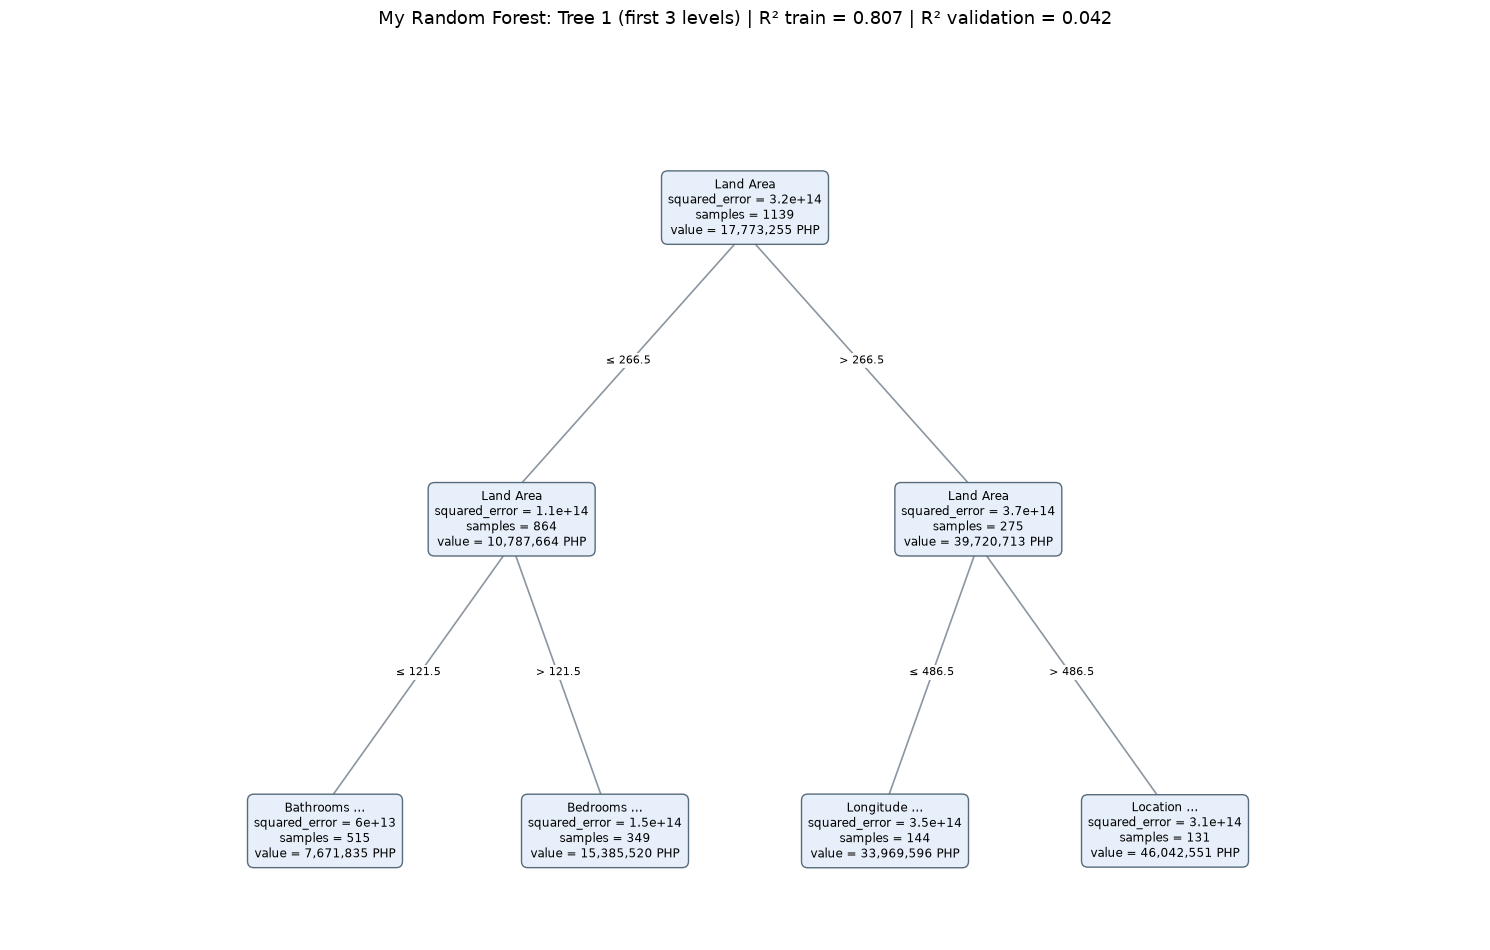

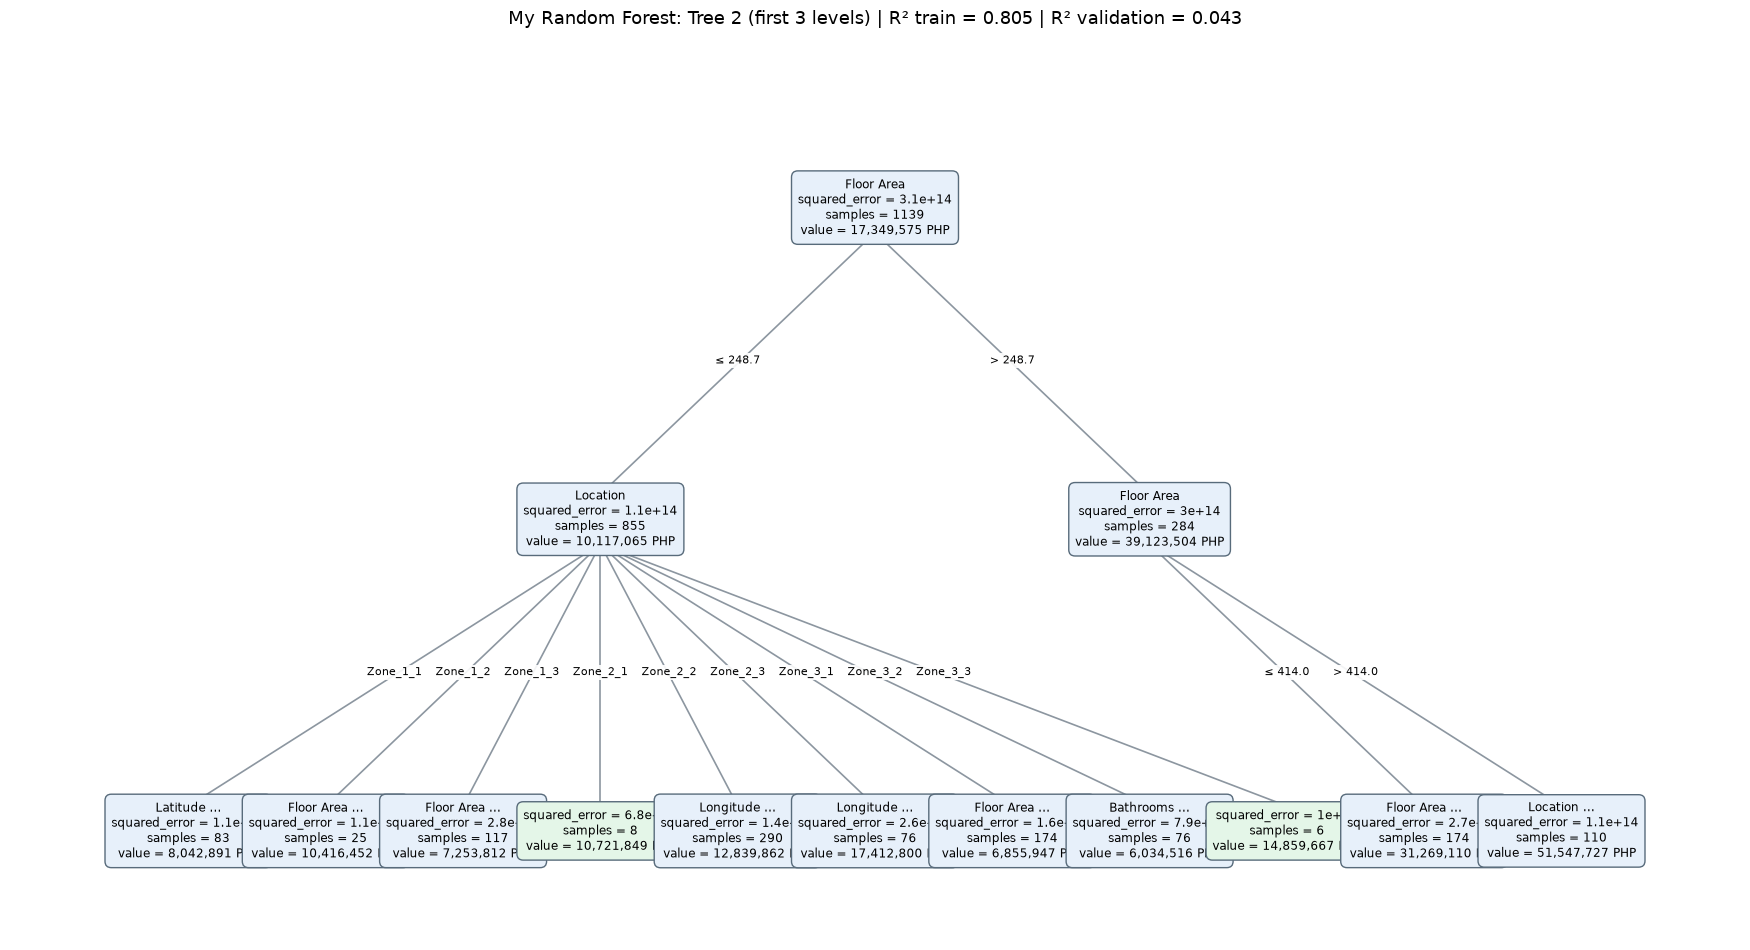

Individual trees in the scikit-learn Random Forest:


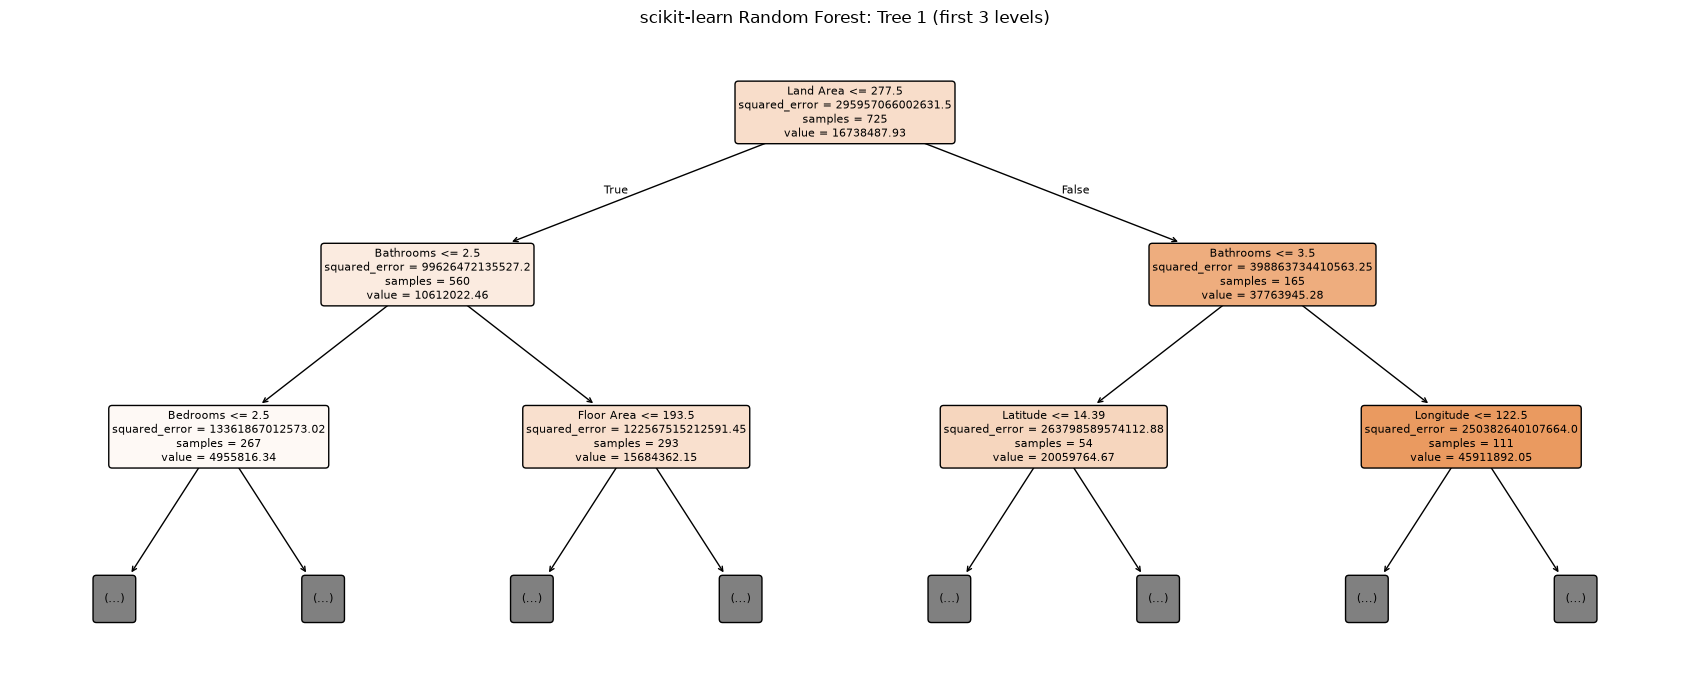

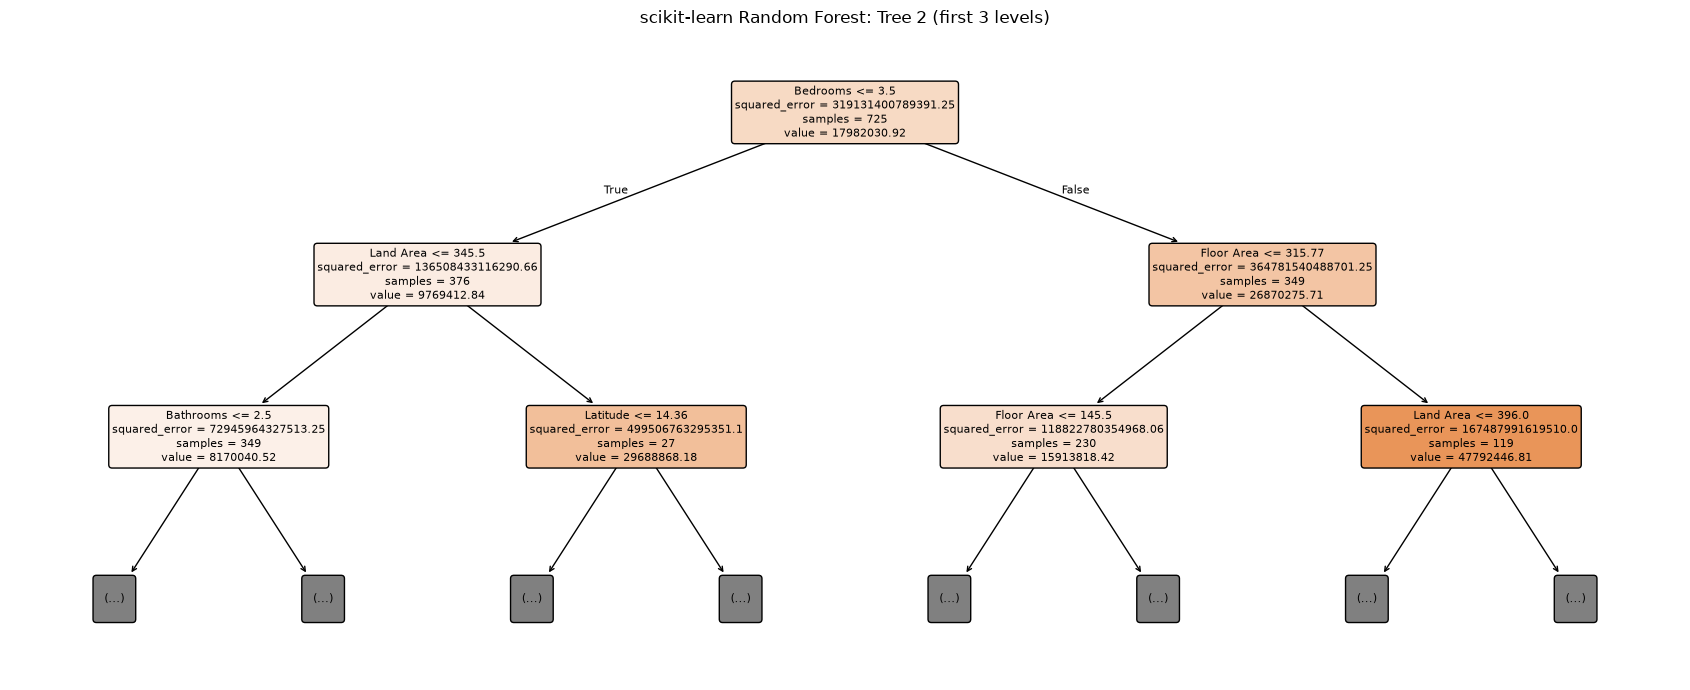

In [43]:
print('Individual trees in my Random Forest:')
for i, tree in enumerate(forest.trees[:2], start=1):
    plot_my_tree(tree, max_depth=3, title=f'My Random Forest: Tree {i}',
                 r2_train=reg_metrics(yd, tree.predict(Xd))['R2'],
                 r2_val=reg_metrics(yt, tree.predict(Xt))['R2'])

print('Individual trees in the scikit-learn Random Forest:')
from sklearn.tree import plot_tree
for i, estimator in enumerate(sk_rf.estimators_[:2], start=1):
    plt.figure(figsize=(17, 7))
    plot_tree(estimator, feature_names=A_final.columns, max_depth=2,
              filled=True, rounded=True, fontsize=8, precision=2)
    plt.title(f'scikit-learn Random Forest: Tree {i} (first 3 levels)')
    plt.tight_layout()
    plt.show()


In [44]:
examples = test_data[FEATS].head(10).copy()

examples['Actual Price'] = yt[:10]
examples['Predicted Price'] = pred[:10]

examples['Absolute Error'] = np.abs(
    examples['Actual Price'] - examples['Predicted Price']
)

examples['Error %'] = np.where(
    examples['Actual Price'] != 0,
    (
        examples['Predicted Price'] - examples['Actual Price']
    ) / examples['Actual Price'] * 100,
    np.nan
)

display(examples.round(2))

import pickle
def to_dict(node):
    return {
        'value': node.value,
        'feat': node.feat,
        'thr': node.thr,
        'kids': {
            key: to_dict(child)
            for key, child in node.kids.items()
        }
    }

saved_model = {
    'prep': prep_final,
    'trees': [to_dict(tree.root) for tree in forest.trees]
}

with open('final_model.pkl', 'wb') as file:
    pickle.dump(saved_model, file)

print("Model saved to final_model.pkl")

,Location,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude,Actual Price,Predicted Price,Absolute Error,Error %
486,"San Sebastian, Kawit",3.0,2.0,80.0,92.0,14.41,120.89,5282600.0,5349987.06,6.738706e+04,1.28
215,"Antero Soriano Highway Sahud Ulan, Tanza",3.0,1.0,45.0,62.0,14.37,120.83,2839149.0,2744125.59,9.502341e+04,-3.35
545,"MacArthur Hwy Anonas, Urdaneta",4.0,3.0,83.0,125.0,16.00,120.58,8328000.0,7643492.89,6.845071e+05,-8.22
964,"Balibago, Angeles",3.0,2.0,185.0,320.0,15.17,120.59,9500000.0,13782634.92,4.282635e+06,45.08
497,"MacArthur Hwy Anonas, Urdaneta",3.0,2.0,66.0,117.0,16.00,120.58,8158000.0,6423479.05,1.734521e+06,-21.26
197,"Emilio Vergara Hwy Santa Arcadia, Cabanatuan",4.0,3.0,85.0,141.0,15.47,120.98,8686000.0,8861607.42,1.756074e+05,2.02
1028,"Bucao St., Nia Village Tandang Sora , Quezon C...",3.0,3.0,119.0,64.0,14.69,121.05,9800000.0,8191103.56,1.608896e+06,-16.42
1471,"Project 8, Quezon City",2.0,1.0,69.0,35.0,14.66,121.02,5000000.0,3765521.32,1.234479e+06,-24.69
1241,"Urdaneta, Makati",5.0,5.0,700.0,1156.0,14.56,121.03,800000000.0,55113571.43,7.448864e+08,-93.11
72,"Aningway Sacatihan, Subic",2.0,1.0,42.0,54.0,14.91,120.23,2605000.0,3347726.63,7.427266e+05,28.51


Model saved to final_model.pkl


In [45]:
%%writefile predict.py
import pickle
import numpy as np
import pandas as pd


FEATS = [
    'Location', 'Bedrooms', 'Bathrooms',
    'Floor Area', 'Land Area', 'Latitude', 'Longitude'
]

# Load the model and preprocessing information from the pickle file
def apply_prep(df, prep):
    medians, modes, bounds, zones = prep
    df = df.copy()

    for col, value in medians.items():
        if col in df.columns:
            df[col] = df[col].fillna(value)

    for col, value in modes.items():
        if col in df.columns:
            df[col] = df[col].fillna(value)

    for col, (low, high) in bounds.items():
        if col in df.columns and col != 'Price':
            df[col] = df[col].clip(low, high)

    # Apply the same geographic zones used during training.
    lat_edges, lon_edges = zones
    lat = pd.to_numeric(df['Latitude'], errors='coerce').to_numpy()
    lon = pd.to_numeric(df['Longitude'], errors='coerce').to_numpy()
    lat_group = np.searchsorted(lat_edges, lat, side='right')
    lon_group = np.searchsorted(lon_edges, lon, side='right')
    df['Location'] = [f'Zone_{a+1}_{b+1}' for a, b in zip(lat_group, lon_group)]
    return df


# Walk through the decision tree to make a prediction for a single row of data
def walk(node, row):
    while node['feat'] is not None:
        value = row[node['feat']]

        if node['thr'] is not None:
            key = 'le' if value <= node['thr'] else 'gt'
        else:
            key = value if value in node['kids'] else '__other__'

        if key not in node['kids']:
            break

        node = node['kids'][key]

    return node['value']


def predict_price(obj):
    with open('final_model.pkl', 'rb') as file:
        model = pickle.load(file)

    df = pd.DataFrame([obj])
    row = apply_prep(df, model['prep']).iloc[0].to_dict()

    predictions = [
        walk(tree, row)
        for tree in model['trees']
    ]

    return float(np.mean(predictions))


if __name__ == '__main__':
    print("Enter house information:")

    obj = {}

    for feature in FEATS:
        value = input(f'{feature}: ').strip()

        if feature == 'Location':
            obj[feature] = value if value else None
        else:
            obj[feature] = float(value) if value else np.nan

    price = predict_price(obj)

    print(f'Predicted price: {price:,.0f} PHP')

Overwriting predict.py


In [46]:
import importlib
import predict

# Reload the updated predict.py
importlib.reload(predict)

sample = test_data.iloc[0][FEATS].to_dict()

saved_prediction = predict.predict_price(sample)
notebook_prediction = pred[0]

print("Original object:")
print(sample)

print("\nPrediction from predict.py:", round(saved_prediction))
print("Prediction from notebook:", round(notebook_prediction))
print("Actual price:", round(test_data.iloc[0]['Price']))

print(
    "\nPredictions match:",
    np.isclose(saved_prediction, notebook_prediction)
)

Original object:
{'Location': 'San Sebastian, Kawit', 'Bedrooms': 3.0, 'Bathrooms': 2.0, 'Floor Area': 80.0, 'Land Area': 92.0, 'Latitude': 14.4129793, 'Longitude': 120.8886677}

Prediction from predict.py: 5349987
Prediction from notebook: 5349987
Actual price: 5282600

Predictions match: True
